# Лабораторная работа №2. Классификация. Нейронные сети

## 1. Введение

**Цель работы** - изучить методы классификации из scikit-learn и нейронную сеть на TensorFlow, включая запись обучения в TensorBoard.

**Задачи:**

1. Подготовить датасет бинарной классификации: разобрать признаки, убрать порченые значения, привести масштабы к виду, который ждёт каждый метод.
2. Обучить пять групп моделей: наивный Байес (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB), дерево решений, линейный дискриминантный анализ, метод опорных векторов, k ближайших соседей.
3. Сравнить их по accuracy, precision, recall, F1 и AUC-ROC.
4. Для каждого метода проследить, как выбранный гиперпараметр меняет качество. Подбор идёт только по обучающей выборке.
5. Собрать полносвязную сеть на TensorFlow, изменить число эпох, размер батча, число слоёв и нейронов, функцию активации и dropout. Кривые обучения и валидации пишутся в TensorBoard.

Положительный класс - серьёзная просрочка в ближайшие два года. Precision здесь - доля настоящих просрочек среди тех, кого модель назвала рискованными. Recall - доля пойманных просрочек среди всех, у кого просрочка случилась. F1 - гармоническое среднее этих двух долей. AUC-ROC не зависит от порога и показывает, умеет ли оценка модели ставить рискованного заёмщика выше благополучного.

Случайность фиксируется: `random_state=42` у разбиения, фолдов и моделей, для сети - `set_random_seed(42)`.

## 2. Выбор и подготовка датасета

Датасет [Credit Risk Benchmark Dataset](https://www.kaggle.com/datasets/adilshamim8/credit-risk-benchmark-dataset). Десять числовых признаков и бинарная цель `dlq_2yrs`: будет ли у заёмщика серьёзная просрочка (90 дней и больше) в ближайшие два года.

Набор полей и служебные коды 96 и 98 совпадают с конкурсом [Give Me Some Credit](https://www.kaggle.com/c/GiveMeSomeCredit). В той исходной выборке просрочка редкая, около 7%. В этой выгрузке классы почти равны, поэтому accuracy можно читать напрямую: она не прячется за преобладанием класса «без просрочки».

| Столбец | Смысл |
|---|---|
| Использование лимита (`rev_util`) | Баланс возобновляемых кредитов, делённый на лимит |
| Возраст (`age`) | Возраст заёмщика, полных лет |
| Просрочки 30-59 (`late_30_59`) | Сколько раз платёж опаздывал на 30-59 дней |
| Долговая нагрузка (`debt_ratio`) | Ежемесячные выплаты по долгам / месячный доход |
| Месячный доход (`monthly_inc`) | Валовый доход в месяц |
| Открытые кредиты (`open_credit`) | Число открытых кредитов и кредитных линий |
| Просрочки 90+ (`late_90`) | Сколько раз просрочка достигала 90 дней и больше |
| Кредиты на жильё (`real_estate`) | Число ипотечных и жилищных линий |
| Просрочки 60-89 (`late_60_89`) | Сколько раз платёж опаздывал на 60-89 дней |
| Иждивенцы (`dependents`) | Число иждивенцев, не считая самого заёмщика |
| Просрочка за 2 года (`dlq_2yrs`) | **Цель:** 1 - серьёзная просрочка в ближайшие 2 года, 0 - нет |

In [1]:
%matplotlib inline
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix,
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.family"] = "Segoe UI"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["figure.dpi"] = 110

SEED = 42
np.random.seed(SEED)

RU_NAMES = {
    "rev_util": "Использование лимита",
    "age": "Возраст",
    "late_30_59": "Просрочки 30-59",
    "debt_ratio": "Долговая нагрузка",
    "monthly_inc": "Месячный доход",
    "open_credit": "Открытые кредиты",
    "late_90": "Просрочки 90+",
    "real_estate": "Кредиты на жильё",
    "late_60_89": "Просрочки 60-89",
    "dependents": "Иждивенцы",
    "late_special": "Код 96/98",
    "dlq_2yrs": "Просрочка за 2 года",
}
BASE_FEATURES = [
    "rev_util", "age", "late_30_59", "debt_ratio", "monthly_inc",
    "open_credit", "late_90", "real_estate", "late_60_89", "dependents",
]
LATE_COLS = ["late_30_59", "late_90", "late_60_89"]
TARGET = "dlq_2yrs"

raw = pd.read_csv("data/credit_risk.csv")
n_null_rows = int(raw.isnull().any(axis=1).sum())
df = raw.dropna().reset_index(drop=True)
n_after_na = len(df)
df = df.drop_duplicates().reset_index(drop=True)

print("=" * 80)
print(f"В файле: {len(raw)} строк, {raw.shape[1]} столбцов")
print(f"Строк с пропусками: {n_null_rows}. После удаления: {n_after_na}")
print(f"Точных дубликатов снято: {n_after_na - len(df)}. Осталось: {len(df)}")
print("=" * 80)
print("\nПервые 5 строк:")
print(df.rename(columns=RU_NAMES).head().to_string(index=False))
print("\nДоля классов:")
shares = df[TARGET].value_counts(normalize=True).sort_index()
counts = df[TARGET].value_counts().sort_index()
for label in shares.index:
    name = "нет просрочки" if label == 0 else "просрочка"
    print(f"  {int(label)} ({name}): {int(counts[label])} строк, {shares[label] * 100:.2f}%")

В файле: 16310 строк, 11 столбцов
Строк с пропусками: 1. После удаления: 16309
Точных дубликатов снято: 2. Осталось: 16307

Первые 5 строк:
 Использование лимита  Возраст  Просрочки 30-59  Долговая нагрузка  Месячный доход  Открытые кредиты  Просрочки 90+  Кредиты на жильё  Просрочки 60-89  Иждивенцы  Просрочка за 2 года
             0.006999     38.0              0.0           0.302150          5440.0               4.0            0.0               1.0              0.0        3.0                  0.0
             0.704592     63.0              0.0           0.471441          8000.0               9.0            0.0               1.0              0.0        0.0                  0.0
             0.063113     57.0              0.0           0.068586          5000.0              17.0            0.0               0.0              0.0        0.0                  0.0
             0.368397     68.0              0.0           0.296273          6250.0              16.0            0.0             

Одна строка в конце файла оборвана: пустые поля начиная с числа открытых кредитов, цели тоже нет. Она выбрасывается целиком. Ещё две анкеты повторены дословно, повтор снят. Остаётся 16307 анкет.

Классы почти равны: 8357 без просрочки (51.25%) и 7950 с просрочкой (48.75%). Это свойство именно этой выгрузки, а не типичный кредитный портфель, где просрочка редкая. Константный ответ «просрочки не будет» даёт accuracy 0.513 и нулевой recall. Любая содержательная модель обязана заметно подняться над этой планкой.

ОПИСАТЕЛЬНАЯ СТАТИСТИКА СЫРЫХ ДАННЫХ
                      Среднее  Станд. откл.  Медиана      IQR  Минимум  Максимум  Асимметрия
Использование лимита     4.90        206.59     0.43     0.84      0.0   22000.0       81.38
Возраст                 48.87         13.95    48.00    20.00     21.0     101.0        0.36
Просрочки 30-59          1.08          7.06     0.00     1.00      0.0      98.0       13.32
Долговая нагрузка       30.98        727.65     0.32     0.38      0.0   61106.5       60.72
Месячный доход        6136.19       5959.21  5000.00  4442.50      0.0  250000.0       12.02
Открытые кредиты         8.50          5.37     8.00     6.00      0.0      57.0        1.18
Просрочки 90+            0.84          7.05     0.00     0.00      0.0      98.0       13.46
Кредиты на жильё         1.05          1.27     1.00     2.00      0.0      29.0        3.60
Просрочки 60-89          0.71          7.02     0.00     0.00      0.0      98.0       13.67
Иждивенцы                0.94    

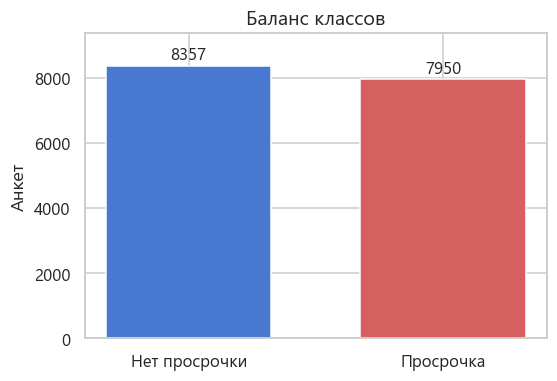

In [2]:
def describe_ru(frame):
    rows = {}
    for col in frame.columns:
        s = frame[col]
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        rows[RU_NAMES[col]] = {
            "Среднее": s.mean(),
            "Станд. откл.": s.std(ddof=1),
            "Медиана": s.median(),
            "IQR": q3 - q1,
            "Минимум": s.min(),
            "Максимум": s.max(),
            "Асимметрия": s.skew(),
        }
    out = pd.DataFrame(rows).T
    print(out.round(2).to_string())
    return out

print("ОПИСАТЕЛЬНАЯ СТАТИСТИКА СЫРЫХ ДАННЫХ")
describe_ru(df[BASE_FEATURES + [TARGET]])

fig, ax = plt.subplots(figsize=(5.2, 3.6))
balance = df[TARGET].value_counts().sort_index()
bars = ax.bar(["Нет просрочки", "Просрочка"], balance.values, color=["C0", "C3"], width=0.65)
for bar, value in zip(bars, balance.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 80, str(int(value)), ha="center", va="bottom")
ax.set_ylabel("Анкет")
ax.set_title("Баланс классов")
ax.set_ylim(0, balance.max() * 1.12)
fig.tight_layout()
plt.show()

### Что чистится и почему

Сырые максимумы не согласуются со смыслом полей. Использование лимита имеет медиану около 0.43, а максимум - 22000. Долговая нагрузка в норме лежит около 0.3, а максимум - десятки тысяч. Три счётчика просрочек принимают значения 96 и 98. В Give Me Some Credit это не «98 раз опоздал», а служебные коды, и они стоят сразу во всех трёх счётчиках.

Такие точки ломают и корреляцию, и методы, которые смотрят на расстояние или на дисперсию. Одна анкета с лимитом 22000 перетягивает среднее и делает коэффициент корреляции использования лимита с целью почти нулевым, хотя по сути связь есть.

Правила очистки, которые не оцениваются по выборке и поэтому применяются до разбиения:

1. Коды 96 и 98 в трёх счётчиках просрочек заменяются на пропуск. Отдельным бинарным признаком `late_special` запоминается, что код стоял: у таких анкет просрочка почти всегда есть, и выбрасывать этот сигнал нельзя.
2. Использование лимита ограничивается сверху двойкой. Значение чуть больше 1 ещё бывает у человека, который вышел за лимит. Значение 10, 300 или 22000 лимитом не является.
3. При нулевом доходе долговая нагрузка не является отношением долга к доходу: в этих строках в поле сидит крупное число. Поле делается пропуском и дальше заполняется медианой обучающей выборки. Сам нулевой доход остаётся.

Медианы пропусков и верхние пороги 99-го перцентиля для долговой нагрузки и дохода считаются **только по обучающей части**, уже после разбиения.


Код 96/98: 84 анкет, доля просрочки среди них 94.0%
Использование лимита > 2: 59 анкет, сырой максимум 22000, после правила максимум 2
Нулевой доход: 174 анкет, долговая нагрузка у них заменена пропуском
Медианы обучающей выборки (ими заполнены пропуски):
Использование лимита       0.431
Возраст                   48.000
Просрочки 30-59            0.000
Долговая нагрузка          0.318
Месячный доход          5000.000
Открытые кредиты           8.000
Просрочки 90+              0.000
Кредиты на жильё           1.000
Просрочки 60-89            0.000
Иждивенцы                  0.000
Код 96/98                  0.000
Верхние пороги 99% обучающей выборки:
  Долговая нагрузка: 3.04
  Месячный доход: 24426.52
Обучающая выборка: 13045 анкет, доля просрочки 48.75%
Тестовая выборка:  3262 анкет, доля просрочки 48.74%


После стандартизации среднее на train -3.53e-17, СКО 1.000
На тесте те же масштабные коэффициенты, среднее уже не обязано быть нулём: 0.001

Корреляция с целью на обучающих строках:
                      До очистки  После очистки
Использование лимита      -0.006          0.466
Возраст                   -0.210         -0.210
Просрочки 30-59            0.120          0.346
Долговая нагрузка         -0.016          0.096
Месячный доход            -0.087         -0.118
Открытые кредиты          -0.053         -0.053
Просрочки 90+              0.107          0.310
Кредиты на жильё          -0.002         -0.002
Просрочки 60-89            0.091          0.283
Иждивенцы                  0.093          0.093
Код 96/98                    NaN          0.067


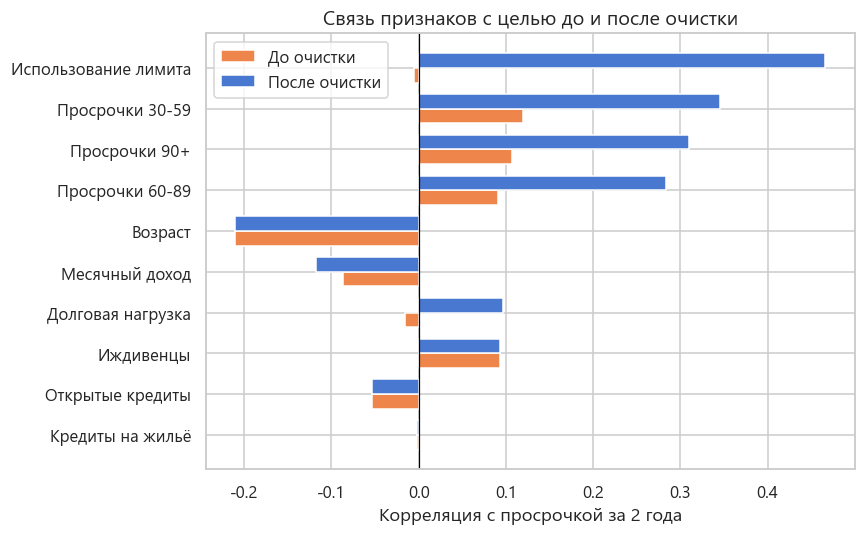


Средние признаки на обучающей выборке:
                      Нет просрочки  Просрочка  Разница
Использование лимита          0.307      0.695    0.388
Возраст                      51.633     45.780   -5.853
Просрочки 30-59               0.204      0.972    0.768
Долговая нагрузка             0.373      0.459    0.085
Месячный доход             6466.096   5469.979 -996.117
Открытые кредиты              8.794      8.219   -0.575
Просрочки 90+                 0.048      0.629    0.582
Кредиты на жильё              1.050      1.045   -0.006
Просрочки 60-89               0.037      0.387    0.350
Иждивенцы                     0.833      1.054    0.221
Код 96/98                     0.001      0.010    0.010


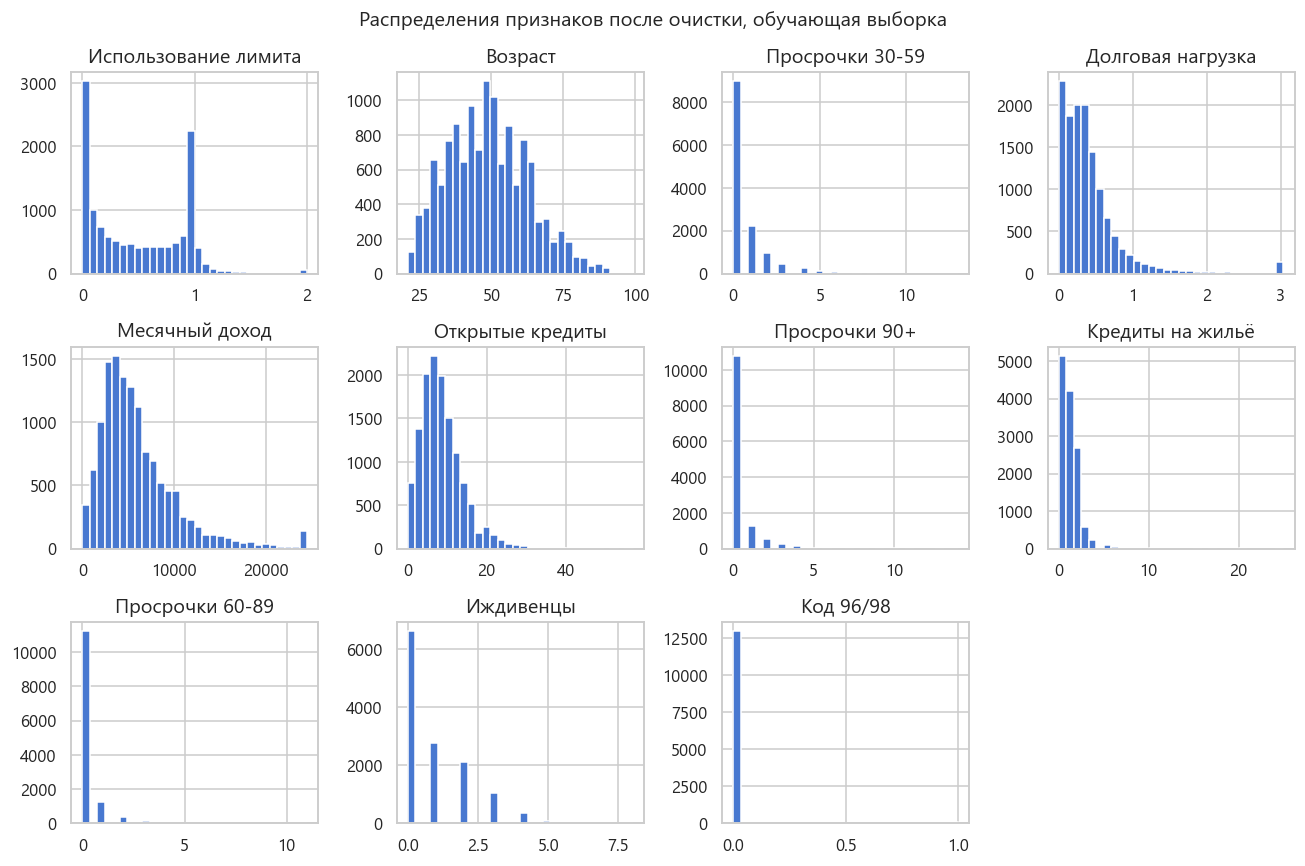

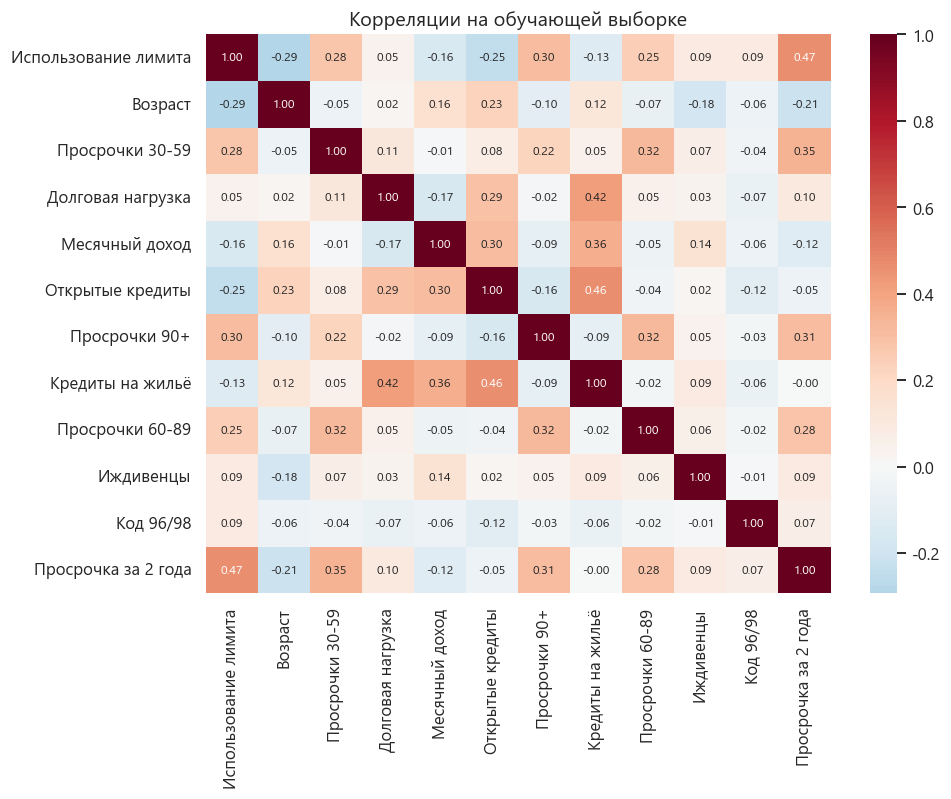

In [3]:
raw_feats = df[BASE_FEATURES].copy()
y_all = df[TARGET].astype(int)

special = df[LATE_COLS].isin([96.0, 98.0]).any(axis=1)
n_special = int(special.sum())
rate_special = float(y_all[special].mean())
df = df.copy()
df["late_special"] = special.astype(int)
for col in LATE_COLS:
    df.loc[df[col].isin([96.0, 98.0]), col] = np.nan

n_rev = int((df["rev_util"] > 2).sum())
rev_max = float(raw_feats["rev_util"].max())
df.loc[df["rev_util"] > 2, "rev_util"] = 2.0

n_zero_inc = int((df["monthly_inc"] <= 0).sum())
df.loc[df["monthly_inc"] <= 0, "debt_ratio"] = np.nan

FEATURE_COLS = BASE_FEATURES + ["late_special"]
X_all = df[FEATURE_COLS]

idx = np.arange(len(df))
idx_tr, idx_te = train_test_split(
    idx, test_size=0.2, stratify=y_all, random_state=SEED
)
X_train = X_all.iloc[idx_tr].copy()
X_test = X_all.iloc[idx_te].copy()
y_train = y_all.iloc[idx_tr].to_numpy()
y_test = y_all.iloc[idx_te].to_numpy()

caps = {}
for col in ["debt_ratio", "monthly_inc"]:
    caps[col] = float(X_train[col].quantile(0.99))
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)
for col, hi in caps.items():
    X_train[col] = X_train[col].clip(upper=hi)
    X_test[col] = X_test[col].clip(upper=hi)

X_train_np = X_train.to_numpy(dtype=float)
X_test_np = X_test.to_numpy(dtype=float)
feat_ru = [RU_NAMES[c] for c in FEATURE_COLS]

scaler = StandardScaler().fit(X_train_np)
X_train_std = scaler.transform(X_train_np)
X_test_std = scaler.transform(X_test_np)

# Псевдосчёты 0..100: на отрезке [0, 1] лапласовское alpha задавило бы частоты.
mm = MinMaxScaler().fit(X_train_np)
X_train_mm = mm.transform(X_train_np) * 100.0
X_test_mm = mm.transform(X_test_np) * 100.0

print("=" * 80)
print(f"Код 96/98: {n_special} анкет, доля просрочки среди них {rate_special * 100:.1f}%")
print(f"Использование лимита > 2: {n_rev} анкет, сырой максимум {rev_max:.0f}, после правила максимум 2")
print(f"Нулевой доход: {n_zero_inc} анкет, долговая нагрузка у них заменена пропуском")
print("Медианы обучающей выборки (ими заполнены пропуски):")
print(medians.rename(index=RU_NAMES).round(3).to_string())
print("Верхние пороги 99% обучающей выборки:")
for col, hi in caps.items():
    print(f"  {RU_NAMES[col]}: {hi:.2f}")
print("=" * 80)
print(f"Обучающая выборка: {len(y_train)} анкет, доля просрочки {y_train.mean() * 100:.2f}%")
print(f"Тестовая выборка:  {len(y_test)} анкет, доля просрочки {y_test.mean() * 100:.2f}%")
print(f"После стандартизации среднее на train {X_train_std.mean():.2e}, СКО {X_train_std.std():.3f}")
print("На тесте те же масштабные коэффициенты, среднее уже не обязано быть нулём: "
      f"{X_test_std.mean():.3f}")

raw_corr = raw_feats.iloc[idx_tr].corrwith(y_all.iloc[idx_tr])
raw_corr.index = [RU_NAMES[c] for c in BASE_FEATURES]
clean_corr = pd.DataFrame(X_train_np, columns=FEATURE_COLS).corrwith(pd.Series(y_train))
clean_corr.index = feat_ru
cmp = pd.DataFrame({"До очистки": raw_corr, "После очистки": clean_corr.reindex(raw_corr.index)})
cmp.loc[RU_NAMES["late_special"], "После очистки"] = clean_corr[RU_NAMES["late_special"]]
print("\nКорреляция с целью на обучающих строках:")
print(cmp.round(3).to_string())

plot_src = cmp.dropna(subset=["До очистки"])
order = plot_src["После очистки"].abs().sort_values().index
fig, ax = plt.subplots(figsize=(8, 5))
plot_df = plot_src.loc[order]
y_pos = np.arange(len(plot_df))
ax.barh(y_pos - 0.18, plot_df["До очистки"], height=0.36, label="До очистки", color="C1")
ax.barh(y_pos + 0.18, plot_df["После очистки"], height=0.36, label="После очистки", color="C0")
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df.index)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Корреляция с просрочкой за 2 года")
ax.set_title("Связь признаков с целью до и после очистки")
ax.legend()
fig.tight_layout()
plt.show()

means = X_train.copy()
means["класс"] = y_train
by_class = means.groupby("класс").mean().T
by_class.index = feat_ru
by_class.columns = ["Нет просрочки", "Просрочка"]
by_class["Разница"] = by_class["Просрочка"] - by_class["Нет просрочки"]
print("\nСредние признаки на обучающей выборке:")
print(by_class.round(3).to_string())

fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for ax, col, title in zip(axes.ravel(), FEATURE_COLS, feat_ru):
    ax.hist(X_train[col], bins=30, color="C0", edgecolor="white")
    ax.set_title(title)
axes.ravel()[-1].axis("off")
fig.suptitle("Распределения признаков после очистки, обучающая выборка")
fig.tight_layout()
plt.show()

corr_df = pd.DataFrame(X_train_np, columns=feat_ru)
corr_df[RU_NAMES[TARGET]] = y_train
fig, ax = plt.subplots(figsize=(9.2, 7.4))
sns.heatmap(
    corr_df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
    annot_kws={"size": 8},
)
ax.set_title("Корреляции на обучающей выборке")
fig.tight_layout()
plt.show()

## 3. Разбиение выборки

`train_test_split` делит анкеты 80/20. `stratify` держит долю просрочки одинаковой, `random_state=42` фиксирует состав. Получилось **13045 обучающих и 3262 тестовых** анкеты, доля просрочки 48.75% и 48.74%. Тестовые строки не участвуют ни в медианах, ни в перцентилях, ни в подборе параметров.

Стандартизация нужна расстояниям, общей ковариации LDA, ядру SVM и сети. Для каждого признака по обучающей выборке считаются среднее \(\mu\) и стандартное отклонение \(\sigma\), затем

\[
z = \frac{x - \mu}{\sigma}.
\]

Те же \(\mu\) и \(\sigma\) применяются к тесту. После преобразования среднее на обучении около нуля, СКО равно 1. На тесте среднее уже 0.001: сдвиг крошечный, но формула и не обещает ноль вне обучающей части.

Дерево на масштаб не смотрит, поэтому получает очищенные исходные числа: порог «доход больше 7000» читается прямо. Мультиномиальный и complement-Байес не принимают отрицательные \(z\)-оценки. Для них очищенная матрица переводится мин-максом на отрезок [0, 100], иначе лапласовское \(\alpha\) порядка единицы задавило бы признаки, лежащие на [0, 1]. Бернуллиев Байес получает бинарные признаки сравнением с квантилью обучающей выборки.

Корреляция с целью на одних и тех же обучающих строках показывает, зачем нужна очистка.

| Признак | До очистки | После очистки |
|---|---:|---:|
| Использование лимита | −0.006 | **+0.466** |
| Просрочки 30-59 | +0.120 | **+0.346** |
| Просрочки 90+ | +0.107 | **+0.310** |
| Просрочки 60-89 | +0.091 | **+0.283** |
| Месячный доход | −0.087 | −0.118 |
| Долговая нагрузка | −0.016 | +0.096 |
| Возраст | −0.210 | −0.210 |

Возраст от правил не меняется: в нём нет ни кода 98, ни выброса в тысячи раз. Лимит и счётчики меняются потому, что 22000 и «98 просрочек» перестают быть обычными числами. После очистки лимит — самый сильный линейный признак. Код 96/98 отдельным столбцом коррелирует с целью только на +0.067: таких анкет 84, хотя внутри группы просрочка у 94%.

Средние на обучающей выборке. У будущей просрочки лимит 0.70 против 0.31, возраст 45.8 против 51.6 лет, доход около 5470 против 6470, просрочек 30-59 в среднем 0.97 против 0.20. Открытых кредитов у них чуть меньше (8.2 против 8.8): риск сидит в загрузке лимита, а не в числе линий. Кредиты на жильё в средних совпали.

Пороги 99% обучающей выборки: долговая нагрузка 3.04, доход 24427. Медиана дохода, которой заполняется нагрузка при нулевом доходе, равна 5000. Медианы счётчиков просрочек равны нулю, поэтому бывший код 98 становится «ноль учтённых просрочек плюс флаг».

Счётчики просрочек коррелируют между собой примерно на 0.2-0.3. Наивный Байес перемножает их как независимые и часть общего сигнала считает трижды. Насколько это стоит качества, видно по сравнению с LDA, который общую ковариацию учитывает.

## 4. Методы классификации

Все пять групп решают одну задачу: по вектору признаков \(x\) оценить, что класс \(y\) равен 1. Порог вероятности везде 0.5. У SVM вероятности нет, там порог - знак отступа до гиперплоскости. Метрики положительного класса:

\[
\mathrm{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN},
\]

\[
\mathrm{Precision} = \frac{TP}{TP + FP}, \quad
\mathrm{Recall} = \frac{TP}{TP + FN}, \quad
F_1 = \frac{2 \cdot \mathrm{Precision} \cdot \mathrm{Recall}}{\mathrm{Precision} + \mathrm{Recall}}.
\]

ROC строится по оценкам, а не по жёстким меткам: порог пробегает все значения, по осям откладываются доля ложных тревог и recall. AUC - площадь под этой кривой. Она равна вероятности, что случайная анкета с просрочкой получит оценку выше случайной анкеты без просрочки.

Подбор у всех методов sklearn устроен одинаково. Сетка параметров оценивается средней AUC на 5 фолдах `StratifiedKFold` (`shuffle=True`, `random_state=42`) по обучающей выборке. Победитель заново учится на всей обучающей выборке. Тест до раздела 7 не открывается.

**Наивный Байес.** По теореме Байеса и при условной независимости признаков

\[
P(y \mid x) \propto P(y) \prod_{j=1}^{p} P(x_j \mid y).
\]

- GaussianNB считает \(P(x_j \mid y)\) нормальной плотностью со своим средним и дисперсией в каждом классе. `var_smoothing` добавляет долю наибольшей дисперсии ко всем дисперсиям, чтобы редкое значение не получало нулевую плотность.
- MultinomialNB и ComplementNB работают с неотрицательными количествами. Сглаживание Лапласа: к счётчику признака в классе добавляется \(\alpha\). ComplementNB оценивает веса по объектам **чужих** классов и за счёт этого меньше залипает на частый класс. Здесь классы и так почти равны, так что большого отрыва у complement быть не обязано.
- BernoulliNB оценивает вероятность, что бинарный признак включён. Непрерывное поле для него переводится в 0/1.

**Дерево решений.** На каждом шаге выбирается признак и порог, которые сильнее всего уменьшают неоднородность узла. Неоднородность - коэффициент Джини \(1 - \sum_k p_k^2\) или энтропия \(-\sum_k p_k \log p_k\). Глубина без ограничения на 13 тысячах строк дорастает до листьев из одной анкеты и запоминает обучающую выборку. `max_depth` и `min_samples_leaf` это обрезают.

**Линейный дискриминантный анализ.** Классы имеют разные средние и одну общую ковариационную матрицу \(\Sigma\). Разделяющая функция линейна:

\[
\delta_k(x) = x^{\top} \Sigma^{-1} \mu_k - \tfrac{1}{2} \mu_k^{\top} \Sigma^{-1} \mu_k + \log \pi_k.
\]

`shrinkage` \(\lambda \in [0, 1]\) подтягивает \(\Sigma\) к диагональной оценке: при \(\lambda = 0\) берётся обычная ковариация, при \(\lambda = 1\) признаки внутри класса считаются некоррелированными. При 11 признаках и 13 тысячах строк \(\Sigma\) и так оценивается устойчиво, поэтому большой выгоды от shrinkage ждать не приходится. Проверка это либо подтвердит, либо опровергнет.

**Метод опорных векторов.** Ищется гиперплоскость с максимальным зазором. Параметр \(C\) - плата за нарушение зазора: малое \(C\) позволяет широкую полосу и больше ошибок на обучении, большое \(C\) прижимает границу к обучающим точкам. Ядро RBF

\[
K(x, x') = \exp(-\gamma \|x - x'\|^2)
\]

строит нелинейную границу. Большое \(\gamma\) делает ядро узким: модель реагирует только на ближайшие точки и легче запоминает шум.

**k ближайших соседей.** Класс анкеты - голос \(k\) ближайших обучающих анкет в стандартизованном пространстве. При \(k = 1\) граница повторяет каждую обучающую точку, в том числе шум. Веса `distance` дают ближайшему соседу больший голос, чем дальнему. Метрика - евклидова или манхэттенская: у второй крупные отклонения по одной координате не возводятся в квадрат.

Веса классов нигде не меняются. Доли 51% и 49% и так близки, `class_weight` почти ничего бы не сдвинул.

## 5. Настройка гиперпараметров

### 5.1. Наивный Байес

У гауссовского варианта меняется `var_smoothing` по логарифмической сетке от \(10^{-12}\) до \(10^{-1}\). У мультиномиального и complement меняется \(\alpha\), у complement ещё и нормировка весов `norm`. У Бернулли вместе с \(\alpha\) меняется квантиль, по которой непрерывный признак становится единицей: 0.25, 0.50 и 0.75. Для счётчиков просрочек медиана равна нулю, поэтому пороги 0.25-0.75 включают признак при любой ненулевой просрочке. Различаются пороги возраста, дохода, лимита и долговой нагрузки.

Гауссовский NB
Лучшие параметры: {'var_smoothing': 0.001}
CV AUC: 0.8440
Мультиномиальный NB
Лучшие параметры: {'alpha': 0.01}
CV AUC: 0.8219


Complement NB
Лучшие параметры: {'alpha': 0.01, 'norm': False}
CV AUC: 0.8219


Бернулли NB, лучший alpha на каждой квантили:
 квантиль  alpha  CV AUC
     0.25   0.10  0.8184
     0.50   0.01  0.8367
     0.75   0.50  0.8171
Выбрана квантиль 0.5, alpha 0.01, CV AUC 0.8367
Пороги выбранной квантили:
Использование лимита       0.431
Возраст                   48.000
Просрочки 30-59            0.000
Долговая нагрузка          0.318
Месячный доход          5000.000
Открытые кредиты           8.000
Просрочки 90+              0.000
Кредиты на жильё           1.000
Просрочки 60-89            0.000
Иждивенцы                  0.000
Код 96/98                  0.000


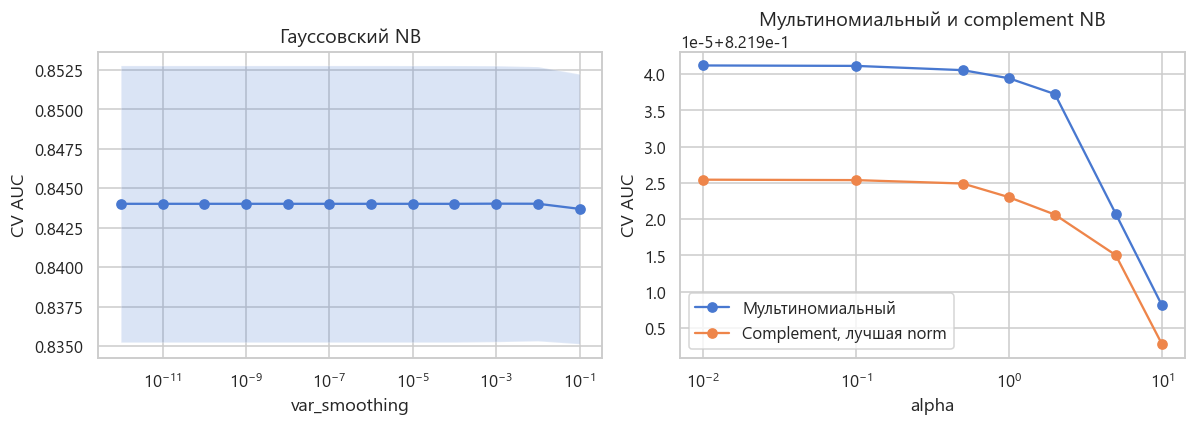

In [4]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
MODELS = {}
TEST_X = {}
SCORE_KIND = {}
CHOSEN = {}
CV_AUC = {}


def plain(value):
    if isinstance(value, dict):
        return {key: plain(item) for key, item in value.items()}
    if isinstance(value, (np.floating, float)):
        return round(float(value), 6)
    if isinstance(value, (np.integer, int)) and not isinstance(value, bool):
        return int(value)
    return value


def run_grid(name, estimator, param_grid, X, X_test, score_kind="proba", train_score=True):
    search = GridSearchCV(
        estimator,
        param_grid,
        scoring="roc_auc",
        cv=CV,
        n_jobs=-1,
        refit=True,
        return_train_score=train_score,
    )
    search.fit(X, y_train)
    MODELS[name] = search.best_estimator_
    TEST_X[name] = X_test
    SCORE_KIND[name] = score_kind
    CHOSEN[name] = plain(dict(search.best_params_))
    CV_AUC[name] = float(search.best_score_)
    print("=" * 80)
    print(name)
    print(f"Лучшие параметры: {CHOSEN[name]}")
    print(f"CV AUC: {search.best_score_:.4f}")
    print("=" * 80)
    return search


def cv_frame(search):
    frame = pd.DataFrame(search.cv_results_)
    return frame


alphas = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
gs_gnb = run_grid(
    "Гауссовский NB",
    GaussianNB(),
    {"var_smoothing": np.logspace(-12, -1, 12)},
    X_train_std, X_test_std,
)
gs_mnb = run_grid(
    "Мультиномиальный NB",
    MultinomialNB(),
    {"alpha": alphas},
    X_train_mm, X_test_mm,
)
gs_cnb = run_grid(
    "Complement NB",
    ComplementNB(),
    {"alpha": alphas, "norm": [False, True]},
    X_train_mm, X_test_mm,
)

bern_rows = []
best_bern = None
for q in (0.25, 0.5, 0.75):
    thr = np.quantile(X_train_np, q, axis=0)
    Xb_tr = (X_train_np > thr).astype(float)
    Xb_te = (X_test_np > thr).astype(float)
    search = GridSearchCV(
        BernoulliNB(),
        {"alpha": alphas},
        scoring="roc_auc",
        cv=CV,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    search.fit(Xb_tr, y_train)
    bern_rows.append({
        "квантиль": q,
        "alpha": search.best_params_["alpha"],
        "CV AUC": search.best_score_,
    })
    if best_bern is None or search.best_score_ > best_bern[0]:
        best_bern = (search.best_score_, search, Xb_te, q, thr)

MODELS["Бернулли NB"] = best_bern[1].best_estimator_
TEST_X["Бернулли NB"] = best_bern[2]
SCORE_KIND["Бернулли NB"] = "proba"
CHOSEN["Бернулли NB"] = {"alpha": best_bern[1].best_params_["alpha"], "квантиль": best_bern[3]}
CV_AUC["Бернулли NB"] = float(best_bern[0])
print("Бернулли NB, лучший alpha на каждой квантили:")
print(pd.DataFrame(bern_rows).round(4).to_string(index=False))
print(f"Выбрана квантиль {best_bern[3]}, alpha {best_bern[1].best_params_['alpha']}, CV AUC {best_bern[0]:.4f}")
print("Пороги выбранной квантили:")
print(pd.Series(best_bern[4], index=feat_ru).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
gnb_res = cv_frame(gs_gnb).sort_values("param_var_smoothing")
axes[0].plot(gnb_res["param_var_smoothing"], gnb_res["mean_test_score"], marker="o")
axes[0].fill_between(
    gnb_res["param_var_smoothing"].astype(float),
    gnb_res["mean_test_score"] - gnb_res["std_test_score"],
    gnb_res["mean_test_score"] + gnb_res["std_test_score"],
    alpha=0.2,
)
axes[0].set_xscale("log")
axes[0].set_xlabel("var_smoothing")
axes[0].set_ylabel("CV AUC")
axes[0].set_title("Гауссовский NB")

for search, label in ((gs_mnb, "Мультиномиальный"), (gs_cnb, "Complement, лучшая norm")):
    res = cv_frame(search)
    # У complement на каждое alpha две norm: берётся лучшая.
    best_by_alpha = res.groupby("param_alpha", as_index=False)["mean_test_score"].max()
    axes[1].plot(best_by_alpha["param_alpha"], best_by_alpha["mean_test_score"], marker="o", label=label)
axes[1].set_xscale("log")
axes[1].set_xlabel("alpha")
axes[1].set_ylabel("CV AUC")
axes[1].set_title("Мультиномиальный и complement NB")
axes[1].legend()
fig.tight_layout()
plt.show()

Четыре варианта разошлись не из-за силы сглаживания, а из-за представления признаков.

У GaussianNB кривая `var_smoothing` плоская: от \(10^{-12}\) до \(10^{-2}\) CV AUC = **0.8440**, при 0.1 она равна 0.8437. Выбранное 0.001 лежит на этом плато. Дисперсии классов оцениваются спокойно, добавка к дисперсии ничего не меняет, пока не становится крупной.

Мультиномиальный NB и ComplementNB совпали: \(\alpha = 0.01\), у complement ещё `norm = False`, CV AUC **0.822**. Классы почти равны, поэтому оценка по «чужим» объектам ничего не сдвигает. Мелкое \(\alpha\) лучше крупного: псевдосчёты уже лежат на шкале 0-100, сильное сглаживание их размазывает.

Бернулли лучше всего режет признаки по медиане, квантиль 0.5 и \(\alpha = 0.01\), CV AUC **0.837**. Квантили 0.25 и 0.75 дают 0.818 и 0.817. Для счётчиков просрочек медиана равна нулю, так что признак включается при любой ненулевой просрочке. Величина при этом теряется: лимит 0.9 и лимит 2 для Бернулли одно и то же, если оба выше 0.43. Отсюда около 0.007 AUC отставания от гауссовского варианта.

### 5.2. Дерево решений

Сетка: критерий Джини или энтропия, глубина 2, 3, 4, 5, 6, 8, 10, 14 и без ограничения, минимум объектов в листе 1, 5, 10, 20, 50. Это 90 комбинаций. На графике глубины лист из одного объекта специально оставлен, чтобы было видно запоминание: AUC на обучении уходит к единице, AUC на фолде после некоторой глубины перестаёт расти и затем падает. В модель берётся не самая глубокая комбинация, а лучшая по фолду.

Дерево решений
Лучшие параметры: {'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 50}
CV AUC: 0.8407
Лучшие 8 комбинаций:
param_criterion param_max_depth  param_min_samples_leaf  mean_test_score  std_test_score  mean_train_score
        entropy               8                      50           0.8407          0.0088            0.8606
           gini               8                      50           0.8400          0.0074            0.8605
        entropy              10                      50           0.8385          0.0093            0.8682
           gini              10                      50           0.8382          0.0076            0.8684
           gini               6                      50           0.8373          0.0081            0.8474
        entropy               6                      50           0.8371          0.0085            0.8478
           gini            None                      50           0.8368          0.0070            0.8735
          

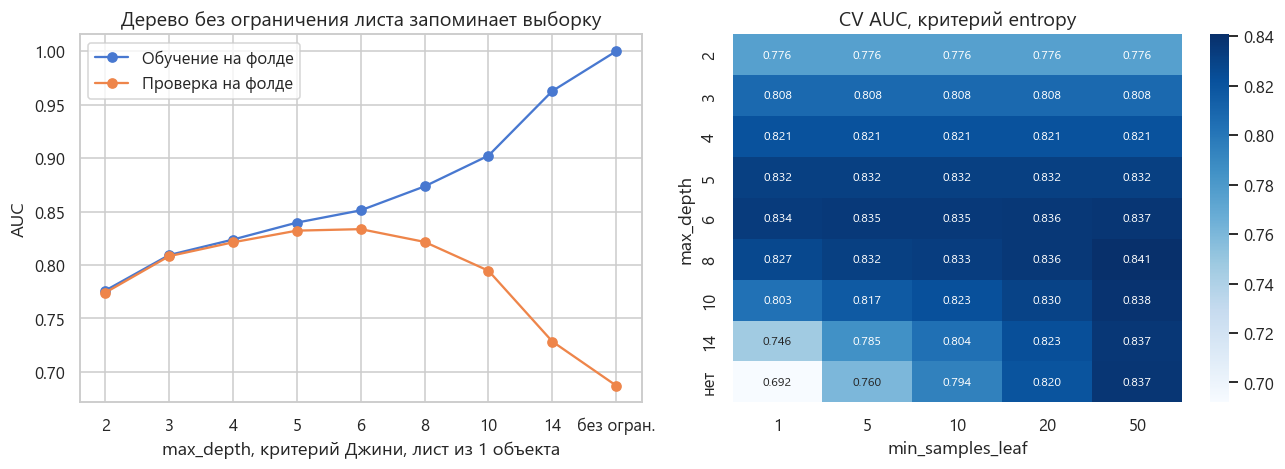

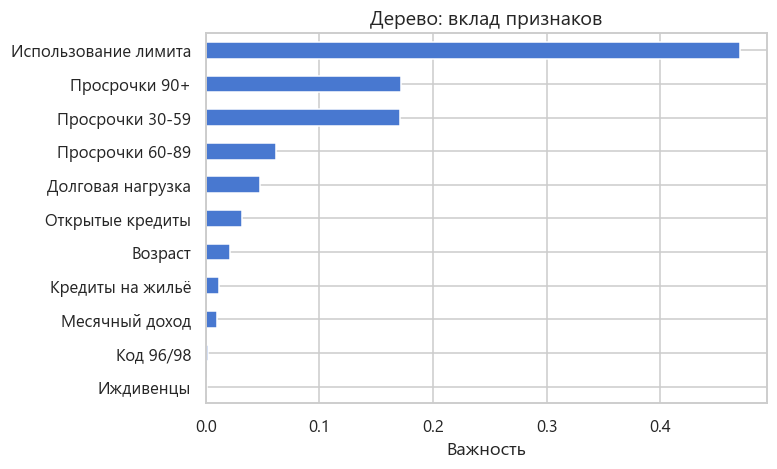

Использование лимита    0.470
Просрочки 90+           0.171
Просрочки 30-59         0.171
Просрочки 60-89         0.062
Долговая нагрузка       0.048
Открытые кредиты        0.032
Возраст                 0.021
Кредиты на жильё        0.011
Месячный доход          0.010
Код 96/98               0.002
Иждивенцы               0.001


In [5]:
depth_grid = [2, 3, 4, 5, 6, 8, 10, 14, None]
gs_tree = run_grid(
    "Дерево решений",
    DecisionTreeClassifier(random_state=SEED),
    {
        "criterion": ["gini", "entropy"],
        "max_depth": depth_grid,
        "min_samples_leaf": [1, 5, 10, 20, 50],
    },
    X_train_np, X_test_np,
)
tree_res = cv_frame(gs_tree)
show_cols = ["param_criterion", "param_max_depth", "param_min_samples_leaf",
             "mean_test_score", "std_test_score", "mean_train_score"]
print("Лучшие 8 комбинаций:")
print(tree_res.sort_values("mean_test_score", ascending=False)[show_cols].head(8).round(4).to_string(index=False))

overfit = tree_res[
    (tree_res["param_criterion"] == "gini") & (tree_res["param_min_samples_leaf"] == 1)
].copy()
overfit["_ord"] = overfit["param_max_depth"].apply(lambda v: 999 if v is None else int(v))
overfit = overfit.sort_values("_ord")
labels = ["без огран." if v is None else str(v) for v in overfit["param_max_depth"]]

best_criterion = gs_tree.best_params_["criterion"]
heat_src = tree_res[tree_res["param_criterion"] == best_criterion].copy()
heat_src["глубина"] = heat_src["param_max_depth"].apply(lambda v: "нет" if v is None else str(int(v)))
heat = heat_src.pivot(index="глубина", columns="param_min_samples_leaf", values="mean_test_score")
heat = heat.reindex([str(d) for d in depth_grid if d is not None] + ["нет"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].plot(range(len(overfit)), overfit["mean_train_score"], marker="o", label="Обучение на фолде")
axes[0].plot(range(len(overfit)), overfit["mean_test_score"], marker="o", label="Проверка на фолде")
axes[0].set_xticks(range(len(overfit)))
axes[0].set_xticklabels(labels)
axes[0].set_xlabel("max_depth, критерий Джини, лист из 1 объекта")
axes[0].set_ylabel("AUC")
axes[0].set_title("Дерево без ограничения листа запоминает выборку")
axes[0].legend()
sns.heatmap(heat, annot=True, fmt=".3f", cmap="Blues", ax=axes[1], annot_kws={"size": 8})
axes[1].set_xlabel("min_samples_leaf")
axes[1].set_ylabel("max_depth")
axes[1].set_title(f"CV AUC, критерий {best_criterion}")
fig.tight_layout()
plt.show()

importances = pd.Series(MODELS["Дерево решений"].feature_importances_, index=feat_ru)
importances = importances.sort_values()
fig, ax = plt.subplots(figsize=(7.2, 4.4))
importances.plot.barh(ax=ax, color="C0")
ax.set_xlabel("Важность")
ax.set_title("Дерево: вклад признаков")
fig.tight_layout()
plt.show()
print(importances.sort_values(ascending=False).round(3).to_string())

Без ограничения листа дерево запоминает выборку. При критерии Джини и `min_samples_leaf = 1` глубина 2 даёт CV AUC 0.774, глубина 6 — 0.834, а снятый лимит дорастает до глубины 30: AUC на обучении **1.00**, на фолде **0.687**. Это хуже, чем дерево глубины 2. На левом графике обучение и проверка расходятся с глубины 6-8.

Лист из 50 объектов это снимает. Лучшая комбинация — **энтропия, глубина 8, `min_samples_leaf = 50`**: CV AUC **0.841** при AUC обучения на фолде 0.861. Джини при тех же глубине и листе даёт 0.840, критерий почти безразличен. Глубже восьми при том же листе уже чуть хуже: глубина 10 — 0.839, глубина без лимита — 0.837.

Важность собрана в использовании лимита (**0.47**) и трёх счётчиках просрочек (0.17, 0.17 и 0.06). Возраст, заметный в LDA, в дереве получает только 0.02: большую часть его сигнала дерево забирает через лимит и прошлые просрочки. Код 96/98 почти не используется (0.002). Таких анкет мало, и лист из 50 объектов ради них не строится.

### 5.3. Линейный дискриминантный анализ

Меняется `shrinkage` от 0 до 1 с шагом 0.1 при солвере `lsqr`. Рядом считается солвер `svd` без стягивания ковариации: это та же модель, что `lsqr` при \(\lambda = 0\), другим численным путём. Если кривая плоская, ковариация на этих данных уже устойчива и регуляризация матрицы ничего не добавляет.

Знак коэффициента читается на стандартизированных признаках: плюс сдвигает решающую функцию в сторону просрочки.

LDA
Лучшие параметры: {'shrinkage': 0.3}
CV AUC: 0.8379
LDA svd, CV AUC: 0.8366 ± 0.0081


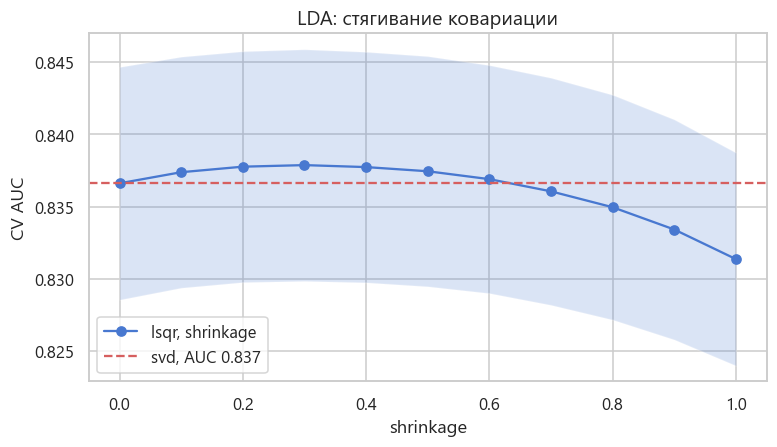

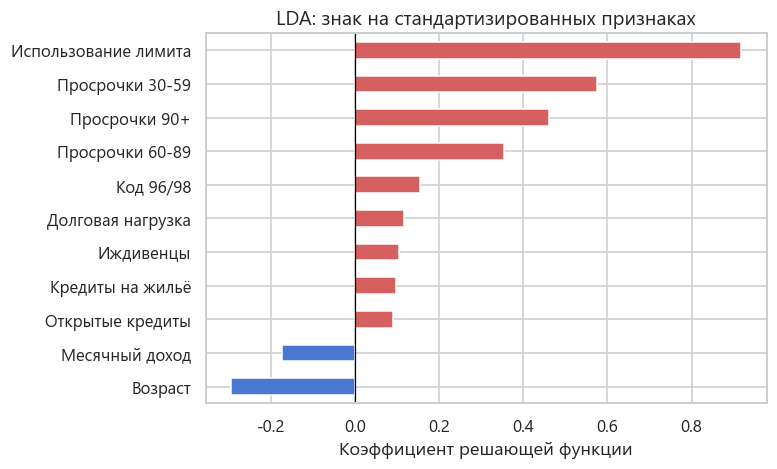

Использование лимита    0.918
Просрочки 30-59         0.576
Просрочки 90+           0.462
Просрочки 60-89         0.353
Код 96/98               0.153
Долговая нагрузка       0.117
Иждивенцы               0.105
Кредиты на жильё        0.097
Открытые кредиты        0.089
Месячный доход         -0.175
Возраст                -0.295


In [6]:
shrink_grid = [round(float(v), 2) for v in np.linspace(0, 1, 11)]
gs_lda = run_grid(
    "LDA",
    LinearDiscriminantAnalysis(solver="lsqr"),
    {"shrinkage": shrink_grid},
    X_train_std, X_test_std,
)
svd = LinearDiscriminantAnalysis(solver="svd")
svd_scores = cross_val_score(svd, X_train_std, y_train, cv=CV, scoring="roc_auc", n_jobs=-1)
print(f"LDA svd, CV AUC: {svd_scores.mean():.4f} ± {svd_scores.std():.4f}")

lda_res = cv_frame(gs_lda).sort_values("param_shrinkage")
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(lda_res["param_shrinkage"], lda_res["mean_test_score"], marker="o", label="lsqr, shrinkage")
ax.fill_between(
    lda_res["param_shrinkage"].astype(float),
    lda_res["mean_test_score"] - lda_res["std_test_score"],
    lda_res["mean_test_score"] + lda_res["std_test_score"],
    alpha=0.2,
)
ax.axhline(svd_scores.mean(), color="C3", linestyle="--", label=f"svd, AUC {svd_scores.mean():.3f}")
ax.set_xlabel("shrinkage")
ax.set_ylabel("CV AUC")
ax.set_title("LDA: стягивание ковариации")
ax.legend()
fig.tight_layout()
plt.show()

lda_coef = pd.Series(MODELS["LDA"].coef_.ravel(), index=feat_ru).sort_values()
fig, ax = plt.subplots(figsize=(7.2, 4.4))
colors = ["C3" if v > 0 else "C0" for v in lda_coef.values]
lda_coef.plot.barh(ax=ax, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Коэффициент решающей функции")
ax.set_title("LDA: знак на стандартизированных признаках")
fig.tight_layout()
plt.show()
print(lda_coef.sort_values(ascending=False).round(3).to_string())

Максимум при **shrinkage = 0.3**, CV AUC **0.838**. При нуле — 0.837, солвер `svd` даёт те же 0.837. Подъём на 0.001 меньше стандартного отклонения фолдов (0.008), отдельным эффектом его считать не стоит. К правому краю кривая уходит вниз монотонно: при shrinkage = 1, когда ковариация заменяется диагональю, AUC **0.831**. Счётчики просрочек связаны между собой, и объявлять их независимыми уже стоит около 0.006 AUC. Сильно тянуть матрицу не нужно.

Коэффициенты на стандартизированных признаках смотрят туда же, куда средние по классам. Плюс у использования лимита (**+0.92**) и просрочек 30-59, 90+ и 60-89 (+0.58, +0.46, +0.35). Минус у возраста (**−0.30**) и дохода (−0.18). Код 96/98 получает +0.15: в тех редких строках, где он равен единице, решающая функция заметно сдвигается к просрочке.

### 5.4. Метод опорных векторов

Линейное ядро - `LinearSVC`, сетка \(C\) от 0.01 до 100. Ядро RBF - `SVC`, сетка \(C \in \{0.1, 1, 10\}\) и \(\gamma \in \{0.01, 0.1, 1, \mathrm{scale}\}\). Обе сетки считаются 5 фолдами на всей обучающей выборке: при 11 признаках один RBF-fit занимает около секунды, урезать данные не нужно.

Оценка для ROC - отступ до гиперплоскости, не вероятность. Accuracy, precision, recall и F1 считаются по знаку этого отступа.

SVM, линейное
Лучшие параметры: {'C': 21.544347}
CV AUC: 0.8470


SVM, RBF
Лучшие параметры: {'C': 1.0, 'gamma': 0.01}
CV AUC: 0.8524


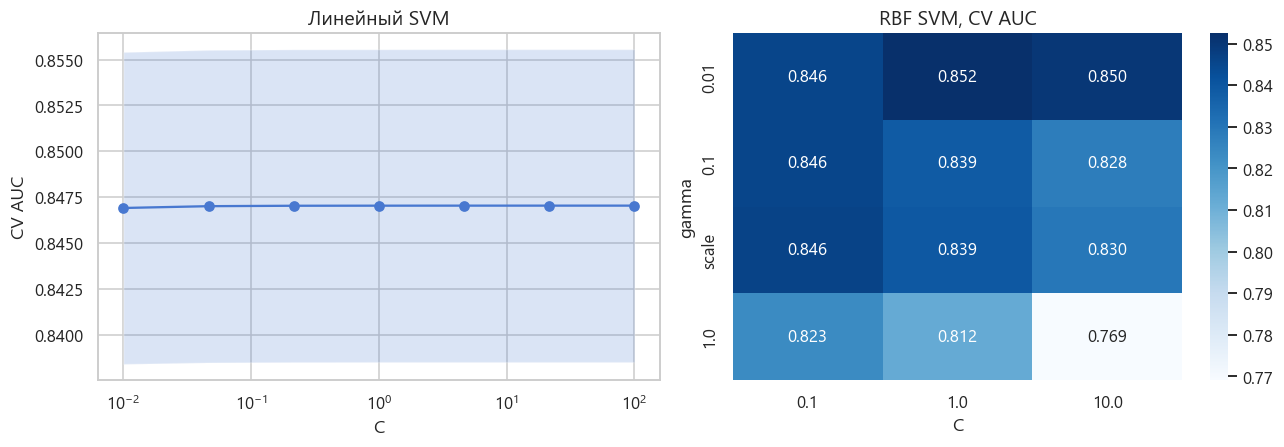

Опорных векторов у RBF: 7021 из 13045 обучающих
RBF при лучшем C, обучение фолда против проверки:
param_gamma  mean_train_score  mean_test_score
       0.01            0.8540           0.8524
      scale            0.8543           0.8395
        0.1            0.8554           0.8387
        1.0            0.9394           0.8124


In [7]:
gs_lin = run_grid(
    "SVM, линейное",
    LinearSVC(dual=False, max_iter=20000, random_state=SEED),
    {"C": np.logspace(-2, 2, 7)},
    X_train_std, X_test_std,
    score_kind="decision",
)
gs_rbf = run_grid(
    "SVM, RBF",
    SVC(kernel="rbf", random_state=SEED),
    {"C": [0.1, 1.0, 10.0], "gamma": [0.01, 0.1, 1.0, "scale"]},
    X_train_std, X_test_std,
    score_kind="decision",
)

lin_res = cv_frame(gs_lin).sort_values("param_C")
rbf_res = cv_frame(gs_rbf)
rbf_heat = rbf_res.pivot(index="param_gamma", columns="param_C", values="mean_test_score")
rbf_heat.index = rbf_heat.index.map(str)
# Порядок гаммы от широкого ядра к узкому.
gamma_order = [g for g in ["0.01", "0.1", "scale", "1.0"] if g in rbf_heat.index]
rbf_heat = rbf_heat.reindex(gamma_order)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(lin_res["param_C"], lin_res["mean_test_score"], marker="o")
axes[0].fill_between(
    lin_res["param_C"].astype(float),
    lin_res["mean_test_score"] - lin_res["std_test_score"],
    lin_res["mean_test_score"] + lin_res["std_test_score"],
    alpha=0.2,
)
axes[0].set_xscale("log")
axes[0].set_xlabel("C")
axes[0].set_ylabel("CV AUC")
axes[0].set_title("Линейный SVM")
sns.heatmap(rbf_heat, annot=True, fmt=".3f", cmap="Blues", ax=axes[1])
axes[1].set_xlabel("C")
axes[1].set_ylabel("gamma")
axes[1].set_title("RBF SVM, CV AUC")
fig.tight_layout()
plt.show()

best_C = gs_rbf.best_params_["C"]
slice_c = rbf_res[rbf_res["param_C"] == best_C].copy()
print(f"Опорных векторов у RBF: {int(MODELS['SVM, RBF'].n_support_.sum())} "
      f"из {len(y_train)} обучающих")
print("RBF при лучшем C, обучение фолда против проверки:")
view = slice_c[["param_gamma", "mean_train_score", "mean_test_score"]].sort_values("mean_test_score", ascending=False)
print(view.round(4).to_string(index=False))

Линейное ядро почти не чувствует \(C\). От 0.01 до 100 кросс-валидация держится на **0.847**. Выбранное \(C = 21.5\) — одна из равных точек, а не острый пик.

У RBF двигает качество ширина ядра. При \(C = 1\) гамма 0.01 даёт CV AUC **0.852** и почти ту же AUC на обучении фолда (0.854). Гамма 1 сужает ядро: обучение поднимается до **0.939**, проверка падает до **0.812**. Это то же запоминание, что у дерева без ограничения глубины, только в радиальном базисе. `gamma='scale'` и 0.1 остаются посередине (0.840 и 0.839).

У выбранного RBF **7021 опорный вектор из 13045** обучающих строк, чуть больше половины. Классы сильно перекрываются, зазор опирается на множество точек. Поэтому линейное ядро отстаёт от лучшего RBF всего на 0.005 AUC: нелинейность есть, но она гладкая. В общее сравнение идут оба ядра, каждое со своими уже выбранными \(C\) и \(\gamma\).

### 5.5. Метод ближайших соседей

Сетка: \(k\) от 1 до 61, веса `uniform` и `distance`, метрика евклидова и манхэттенская. Признаки стандартизированы, иначе доход в абсолютных единицах задавил бы возраст и счётчики просрочек.

Отдельно считается AUC на самой обучающей выборке. Для весов `distance` она равна единице при любом \(k\): ближайший сосед точки — она сама, расстояние ноль, вес этой точки бесконечный. Это тождество, а не оценка качества. Качество — только AUC на фолдах.

kNN
Лучшие параметры: {'metric': 'manhattan', 'n_neighbors': 61, 'weights': 'distance'}
CV AUC: 0.8444
Лучшие 8 комбинаций:
 param_n_neighbors param_weights param_metric  mean_test_score  std_test_score
                61      distance    manhattan           0.8444          0.0070
                61      distance    euclidean           0.8444          0.0067
                61       uniform    manhattan           0.8439          0.0067
                61       uniform    euclidean           0.8437          0.0064
                41      distance    euclidean           0.8430          0.0075
                41       uniform    euclidean           0.8424          0.0074
                41      distance    manhattan           0.8422          0.0072
                41       uniform    manhattan           0.8417          0.0070


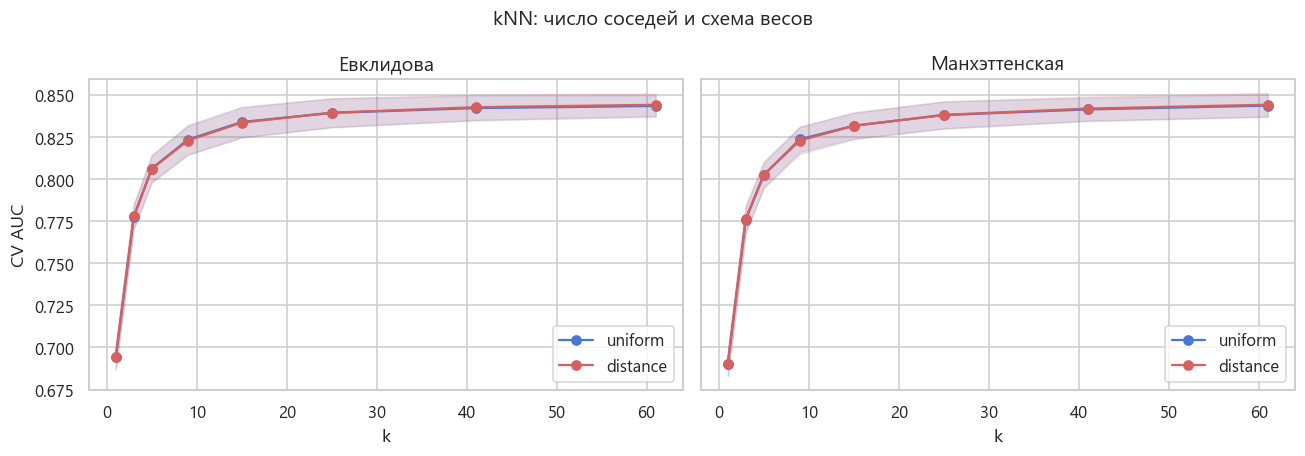

AUC на обучении, k=1, weights=uniform, metric=manhattan: 1.0000


AUC на обучении, k=61, weights=distance, metric=manhattan: 1.0000
Для weights=distance это тождество, а не качество: ближайший сосед обучающей точки — она сама,
расстояние равно нулю и её вес подавляет остальных. Обобщение видно только по AUC на фолдах.


In [8]:
k_grid = [1, 3, 5, 9, 15, 25, 41, 61]
gs_knn = run_grid(
    "kNN",
    KNeighborsClassifier(),
    {
        "n_neighbors": k_grid,
        "weights": ["uniform", "distance"],
        "metric": ["euclidean", "manhattan"],
    },
    X_train_std, X_test_std,
    train_score=False,
)
knn_res = cv_frame(gs_knn)
print("Лучшие 8 комбинаций:")
print(
    knn_res.sort_values("mean_test_score", ascending=False)[
        ["param_n_neighbors", "param_weights", "param_metric", "mean_test_score", "std_test_score"]
    ].head(8).round(4).to_string(index=False)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, metric in zip(axes, ["euclidean", "manhattan"]):
    for weights, color in (("uniform", "C0"), ("distance", "C3")):
        part = knn_res[
            (knn_res["param_metric"] == metric) & (knn_res["param_weights"] == weights)
        ].sort_values("param_n_neighbors")
        ax.plot(part["param_n_neighbors"], part["mean_test_score"], marker="o", color=color, label=weights)
        ax.fill_between(
            part["param_n_neighbors"].astype(float),
            part["mean_test_score"] - part["std_test_score"],
            part["mean_test_score"] + part["std_test_score"],
            alpha=0.15, color=color,
        )
    ax.set_xlabel("k")
    ax.set_title("Евклидова" if metric == "euclidean" else "Манхэттенская")
    ax.legend()
axes[0].set_ylabel("CV AUC")
fig.suptitle("kNN: число соседей и схема весов")
fig.tight_layout()
plt.show()

best_k = int(gs_knn.best_params_["n_neighbors"])
best_w = gs_knn.best_params_["weights"]
best_m = gs_knn.best_params_["metric"]
for k, weights in ((1, "uniform"), (best_k, best_w)):
    probe = KNeighborsClassifier(n_neighbors=k, weights=weights, metric=best_m)
    probe.fit(X_train_std, y_train)
    train_auc = roc_auc_score(y_train, probe.predict_proba(X_train_std)[:, 1])
    print(f"AUC на обучении, k={k}, weights={weights}, metric={best_m}: {train_auc:.4f}")
print("Для weights=distance это тождество, а не качество: ближайший сосед обучающей точки — она сама,")
print("расстояние равно нулю и её вес подавляет остальных. Обобщение видно только по AUC на фолдах.")

Качество растёт вместе с \(k\). В верхней части сетки только окрестности 41 и 61. Лучшая комбинация — **\(k = 61\)**, манхэттенская метрика, веса `distance`, CV AUC **0.844**. Евклидова метрика при том же \(k\) и тех же весах даёт те же 0.844. Схема `uniform` против `distance` на этом \(k\) — 0.8439 против 0.8444. Ни метрика, ни веса здесь не решают. Решает размер окрестности: мелкие \(k\) в восьмёрку лучших не входят.

AUC на обучении равна 1.000 и при \(k = 1\), и при выбранных \(k = 61\). Для `distance` иначе быть не может, это записано в выводе ячейки. Смотреть на переобучение здесь можно только по фолдам, и они как раз наказывают маленькую окрестность.

## 6. Нейронная сеть на TensorFlow

Сеть полносвязная, задача та же бинарная. На вход подаются 11 стандартизированных признаков. Скрытые слои - `Dense` с общей функцией активации. После каждого скрытого слоя стоит `Dropout`: на шаге обучения он зануляет долю нейронов, чтобы сеть не держалась за одну случайную связь. Выход - один нейрон с сигмоидой

\[
\hat p = \sigma(w^{\top} h + b), \quad \sigma(z) = \frac{1}{1 + e^{-z}}.
\]

Потеря - бинарная кросс-энтропия, оптимизатор - Adam с шагом \(10^{-3}\). Метрики эпохи - accuracy и AUC.

От обучающей выборки отрезается стратифицированные 20% и фиксируются как валидация. По ним выбираются гиперпараметры и эпоха. Тест по-прежнему не смотрится. Базовая конфигурация: два скрытых слоя 64 и 32, ReLU, dropout 0.2, батч 64, 30 эпох. Остальные опыты меняют **один** фактор относительно базы, чтобы сдвиг AUC можно было приписать этому фактору.

Каждый опыт пишет скаляры в свой каталог `logs/nn/<имя>`. Сравнение кривых в интерфейсе:

```text
tensorboard --logdir logs
```

В ноутбуке те же величины нарисованы из `history`, чтобы отчёт читался без запущенного TensorBoard. Финальная сеть с лучшей по валидации конфигурацией учится заново на **всей** обучающей выборке, число эпох - то, на котором у этого опыта валидационная AUC была максимальной. Её прогноз идёт в общее сравнение.

Для сети: обучение 10436, валидация 2609, доля просрочки на валидации 48.75%


База: 64-32, ReLU, dropout 0.2, батч 64: val AUC 0.8589 на эпохе 9, val loss 0.4704, val accuracy 0.7846


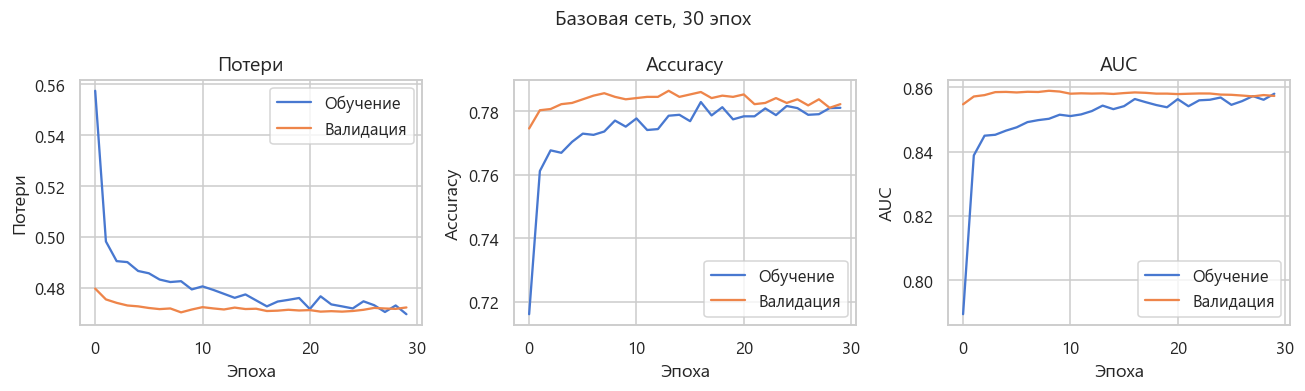

Батч 32: val AUC 0.8594 на эпохе 3, val loss 0.4714, val accuracy 0.7842


Батч 256: val AUC 0.8589 на эпохе 11, val loss 0.4714, val accuracy 0.7842


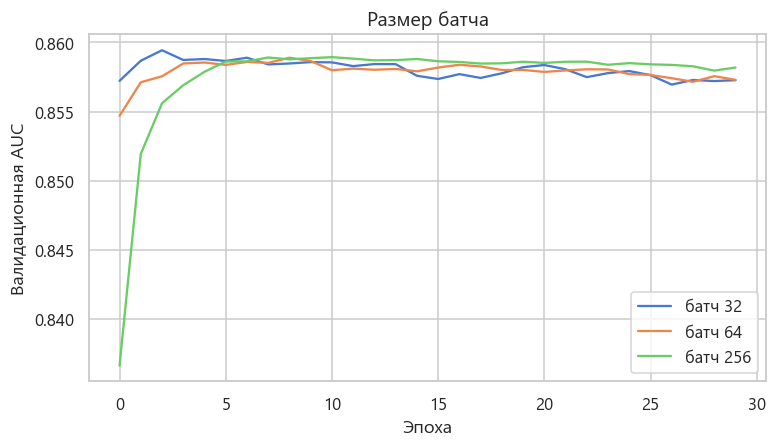

Один слой, 32 нейрона: val AUC 0.8597 на эпохе 14, val loss 0.4703, val accuracy 0.7838


Два слоя, 128-64: val AUC 0.8593 на эпохе 7, val loss 0.4696, val accuracy 0.7827


Три слоя, 128-64-32: val AUC 0.8593 на эпохе 6, val loss 0.4708, val accuracy 0.7815


Активация tanh: val AUC 0.8591 на эпохе 29, val loss 0.4695, val accuracy 0.7846


Активация sigmoid: val AUC 0.8577 на эпохе 29, val loss 0.4714, val accuracy 0.7842


Без dropout: val AUC 0.8587 на эпохе 3, val loss 0.4724, val accuracy 0.7831


Dropout 0.5: val AUC 0.8586 на эпохе 10, val loss 0.4734, val accuracy 0.7846

Все опыты сети, сортировка по валидационной AUC:
                                  title        hidden activation  dropout  batch_size  best_epoch  val_auc  val_loss  val_accuracy
                  Один слой, 32 нейрона         (32,)       relu      0.2          64          14   0.8597    0.4703        0.7838
                                Батч 32      (64, 32)       relu      0.2          32           3   0.8594    0.4714        0.7842
                    Три слоя, 128-64-32 (128, 64, 32)       relu      0.2          64           6   0.8593    0.4708        0.7815
                       Два слоя, 128-64     (128, 64)       relu      0.2          64           7   0.8593    0.4696        0.7827
                         Активация tanh      (64, 32)       tanh      0.2          64          29   0.8591    0.4695        0.7846
                               Батч 256      (64, 32)       relu      0.2         256 

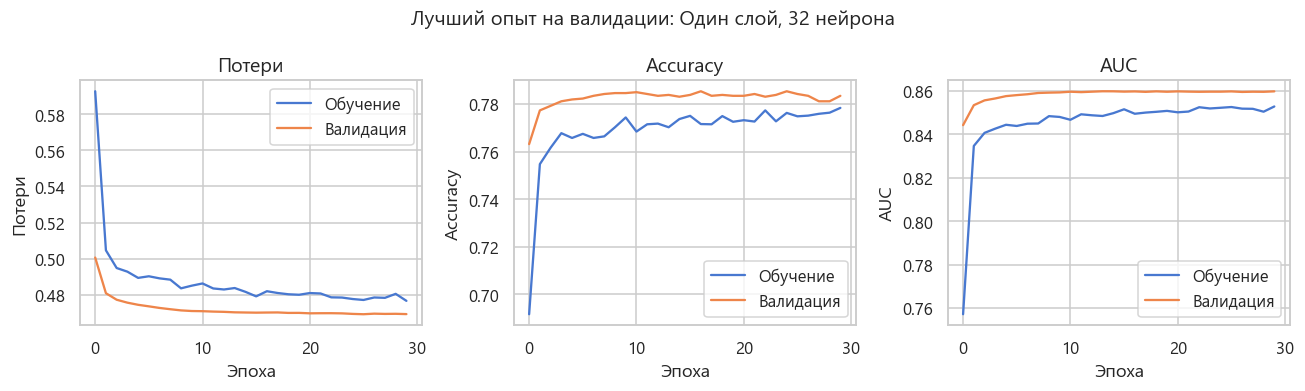

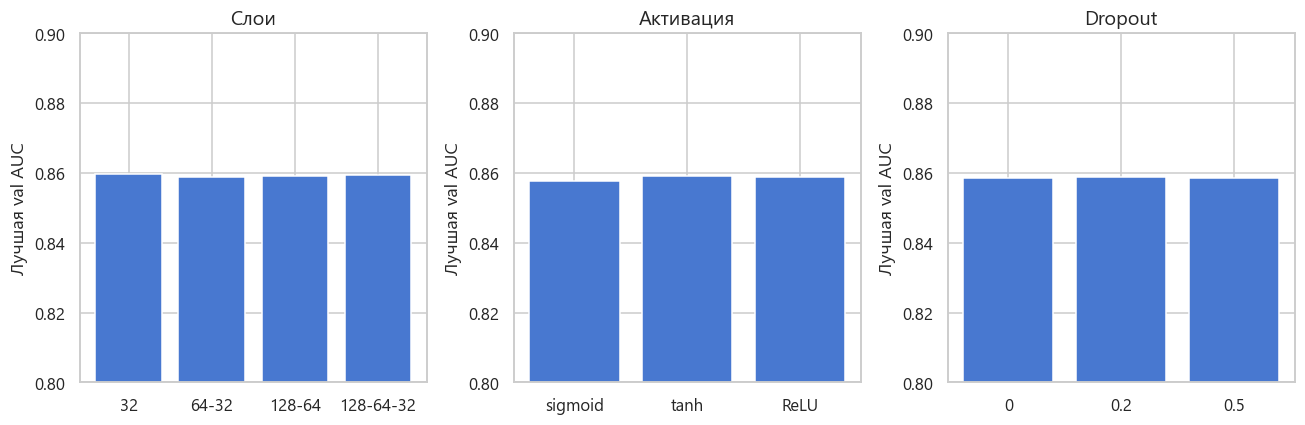

In [9]:
import warnings
warnings.filterwarnings("ignore", message=".*GPU support is not available.*")
warnings.filterwarnings("ignore", message=".*reset_default_graph.*")

import tensorflow as tf

tf.get_logger().setLevel("ERROR")
tf.keras.utils.set_random_seed(SEED)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_std, y_train, test_size=0.2, stratify=y_train, random_state=SEED
)
y_tr = y_tr.astype("float32")
y_val = y_val.astype("float32")
print(f"Для сети: обучение {len(y_tr)}, валидация {len(y_val)}, "
      f"доля просрочки на валидации {y_val.mean() * 100:.2f}%")

NN_EPOCHS = 30
nn_runs = []


def build_model(hidden, activation, dropout, lr=1e-3):
    layers = [tf.keras.layers.Input(shape=(X_train_std.shape[1],))]
    for units in hidden:
        layers.append(tf.keras.layers.Dense(units, activation=activation))
        if dropout > 0:
            layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))
    model = tf.keras.Sequential(layers)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
    )
    return model


def run_nn(tag, title, hidden, activation="relu", dropout=0.2, batch_size=64, epochs=NN_EPOCHS):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(hidden, activation, dropout)
    log_dir = os.path.join("logs", "nn", tag)
    board = tf.keras.callbacks.TensorBoard(
        log_dir=log_dir, histogram_freq=0, write_graph=True, profile_batch=0,
    )
    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[board],
        verbose=0,
    )
    hist = history.history
    best_i = int(np.argmax(hist["val_auc"]))
    row = {
        "tag": tag,
        "title": title,
        "hidden": hidden,
        "activation": activation,
        "dropout": dropout,
        "batch_size": batch_size,
        "best_epoch": best_i + 1,
        "val_auc": float(hist["val_auc"][best_i]),
        "val_loss": float(hist["val_loss"][best_i]),
        "val_accuracy": float(hist["val_accuracy"][best_i]),
        "history": hist,
    }
    nn_runs.append(row)
    print(
        f"{title}: val AUC {row['val_auc']:.4f} на эпохе {row['best_epoch']}, "
        f"val loss {row['val_loss']:.4f}, val accuracy {row['val_accuracy']:.4f}"
    )
    return row


def plot_history(hist, title):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
    for ax, key, label in zip(
        axes, ["loss", "accuracy", "auc"], ["Потери", "Accuracy", "AUC"]
    ):
        ax.plot(hist[key], label="Обучение")
        ax.plot(hist[f"val_{key}"], label="Валидация")
        ax.set_xlabel("Эпоха")
        ax.set_ylabel(label)
        ax.set_title(label)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


base = run_nn("baseline", "База: 64-32, ReLU, dropout 0.2, батч 64", (64, 32))
plot_history(base["history"], "Базовая сеть, 30 эпох")

for batch, tag in ((32, "batch_32"), (256, "batch_256")):
    run_nn(tag, f"Батч {batch}", (64, 32), batch_size=batch)

fig, ax = plt.subplots(figsize=(7.2, 4.2))
for tag, label in (
    ("batch_32", "батч 32"),
    ("baseline", "батч 64"),
    ("batch_256", "батч 256"),
):
    hist = next(row["history"] for row in nn_runs if row["tag"] == tag)
    ax.plot(hist["val_auc"], label=label)
ax.set_xlabel("Эпоха")
ax.set_ylabel("Валидационная AUC")
ax.set_title("Размер батча")
ax.legend()
fig.tight_layout()
plt.show()

run_nn("arch_32", "Один слой, 32 нейрона", (32,))
run_nn("arch_wide", "Два слоя, 128-64", (128, 64))
run_nn("arch_deep", "Три слоя, 128-64-32", (128, 64, 32))
run_nn("act_tanh", "Активация tanh", (64, 32), activation="tanh")
run_nn("act_sigmoid", "Активация sigmoid", (64, 32), activation="sigmoid")
run_nn("drop_0", "Без dropout", (64, 32), dropout=0.0)
run_nn("drop_05", "Dropout 0.5", (64, 32), dropout=0.5)

summary = pd.DataFrame(nn_runs).drop(columns=["history"])
summary = summary.sort_values("val_auc", ascending=False)
print("\nВсе опыты сети, сортировка по валидационной AUC:")
print(summary.drop(columns=["tag"]).round(4).to_string(index=False))

best_nn = max(nn_runs, key=lambda row: row["val_auc"])
if best_nn["tag"] != "baseline":
    plot_history(best_nn["history"], f"Лучший опыт на валидации: {best_nn['title']}")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
groups = [
    ("Слои", ["arch_32", "baseline", "arch_wide", "arch_deep"],
     ["32", "64-32", "128-64", "128-64-32"]),
    ("Активация", ["act_sigmoid", "act_tanh", "baseline"],
     ["sigmoid", "tanh", "ReLU"]),
    ("Dropout", ["drop_0", "baseline", "drop_05"],
     ["0", "0.2", "0.5"]),
]
by_tag = {row["tag"]: row for row in nn_runs}
for ax, (title, tags, labels) in zip(axes, groups):
    vals = [by_tag[tag]["val_auc"] for tag in tags]
    ax.bar(labels, vals, color="C0")
    ax.set_ylim(0.80, 0.90)
    ax.set_ylabel("Лучшая val AUC")
    ax.set_title(title)
fig.tight_layout()
plt.show()

In [10]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
final_nn = build_model(best_nn["hidden"], best_nn["activation"], best_nn["dropout"])
final_nn.fit(
    X_train_std, y_train.astype("float32"),
    epochs=int(best_nn["best_epoch"]),
    batch_size=int(best_nn["batch_size"]),
    callbacks=[tf.keras.callbacks.TensorBoard(
        log_dir=os.path.join("logs", "nn", "final"),
        histogram_freq=0, write_graph=True, profile_batch=0,
    )],
    verbose=0,
)
print("Финальная сеть")
print(f"  слои: {best_nn['hidden']}, активация: {best_nn['activation']}")
print(f"  dropout: {best_nn['dropout']}, батч: {best_nn['batch_size']}, эпох: {best_nn['best_epoch']}")
print(f"  валидационная AUC выбранного опыта: {best_nn['val_auc']:.4f}")
final_nn.summary()

nn_score = final_nn.predict(X_test_std, verbose=0).ravel()
nn_pred = (nn_score >= 0.5).astype(int)
CHOSEN["Нейросеть"] = {
    "слои": best_nn["hidden"],
    "активация": best_nn["activation"],
    "dropout": best_nn["dropout"],
    "батч": best_nn["batch_size"],
    "эпохи": best_nn["best_epoch"],
}
CV_AUC["Нейросеть"] = float(best_nn["val_auc"])

Финальная сеть
  слои: (32,), активация: relu
  dropout: 0.2, батч: 64, эпох: 14
  валидационная AUC выбранного опыта: 0.8597


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,253 (4.90 KB)

 Trainable params: 417 (1.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 836 (3.27 KB)

Валидационная AUC всех десяти опытов лежит между **0.8577 и 0.8597**. На столбчатой диаграмме шкала начинается с 0.80, и столбцы почти одной высоты: разница лучшего и худшего опыта 0.002.

**Эпохи.** Базовая сеть с ReLU достигает максимума на 9-й эпохе (val AUC 0.8589). Оставшиеся эпохи из тридцати качество уже не поднимают. Tanh и sigmoid доходят до своего лучшего значения только на 29-й эпохе: они медленнее. Sigmoid за эти 30 эпох последний (0.8577). Это разница скорости, а не доказательство, что при более длинном обучении sigmoid не догонит ReLU.

**Батч.** 32, 64 и 256 дают 0.8594, 0.8589 и 0.8589. Меньший батч выходит на пик раньше (3-я эпоха против 11-й у батча 256), потому что за эпоху делает больше шагов Adam. Итоговая AUC от размера батча здесь не зависит.

**Слои и нейроны.** Один слой из 32 нейронов — 0.8597 на 14-й эпохе. Два слоя 64-32 — 0.8589, два слоя 128-64 — 0.8593, три слоя 128-64-32 — 0.8593. Углубление и расширение AUC не прибавляют. Одной нелинейности на этих признаках достаточно, что стыкуется с гладким ядром SVM из раздела 5.4.

**Dropout.** На базовой архитектуре значения 0, 0.2 и 0.5 дают 0.8587, 0.8589 и 0.8586. Сеть маленькая относительно 10 тысяч строк, занулять нейроны незачем. В финальную модель dropout 0.2 попал потому, что он стоял в победившем однослойном опыте, а не потому, что без него результат хуже.

Правило выбора было зафиксировано до теста: берётся опыт с наибольшей валидационной AUC и эпоха этого максимума. Это один скрытый слой на 32 нейрона, ReLU, dropout 0.2, батч 64, **14 эпох**. Сеть заново учится на всех 13045 обучающих строках. Журналы опытов лежат в `logs/nn/` и открываются командой `tensorboard --logdir logs`: там те же loss, accuracy и AUC, что на графиках выше.

## 7. Сравнительный анализ

В таблице каждая модель со своими уже выбранными параметрами, один проход по тестовой выборке. Для вероятностных моделей порог 0.5. Для обоих SVM метка - знак отступа. Precision, recall и F1 посчитаны для класса «просрочка», без макроусреднения: задача в том, чтобы находить именно этот класс.

Колонка «AUC на подборе» - средняя AUC пяти фолдов. У сети это лучшая валидационная AUC опыта, который победил среди однофакторных конфигураций. Числа одной природы, но схема другая, поэтому сеть с фолдовыми моделями по этой колонке не ранжируется. Ранжирование общее - по тестовой AUC.

Константный классификатор всегда отвечает «просрочки нет». Его accuracy равна доли класса 0 на тесте, recall равен нулю, AUC равна 0.5. Это нижняя планка, не участник подбора.

ТЕСТОВЫЕ МЕТРИКИ
                     Accuracy  Precision  Recall      F1  AUC-ROC  AUC на подборе
Модель                                                                           
Нейросеть              0.7777     0.7774  0.7623  0.7698   0.8544          0.8597
SVM, RBF               0.7765     0.7911  0.7358  0.7625   0.8530          0.8524
SVM, линейное          0.7676     0.7869  0.7176  0.7507   0.8464          0.8470
kNN                    0.7544     0.8000  0.6616  0.7243   0.8443          0.8444
Дерево решений         0.7649     0.7896  0.7057  0.7453   0.8434          0.8407
Гауссовский NB         0.7259     0.8718  0.5132  0.6461   0.8405          0.8440
LDA                    0.7514     0.7714  0.6962  0.7319   0.8355          0.8379
Бернулли NB            0.7532     0.7790  0.6893  0.7314   0.8336          0.8367
Complement NB          0.7551     0.7714  0.7069  0.7378   0.8199          0.8219
Мультиномиальный NB    0.7548     0.7713  0.7063  0.7374   0.8199          0.8219

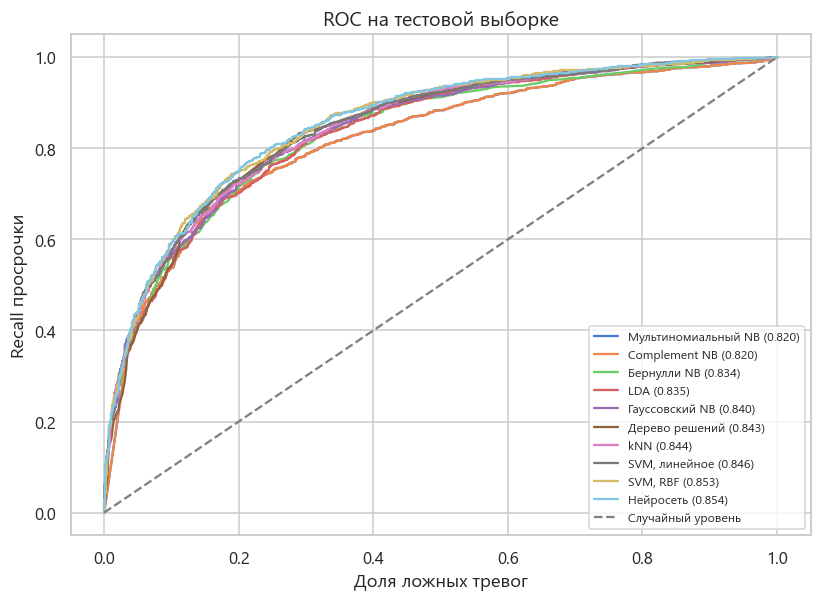

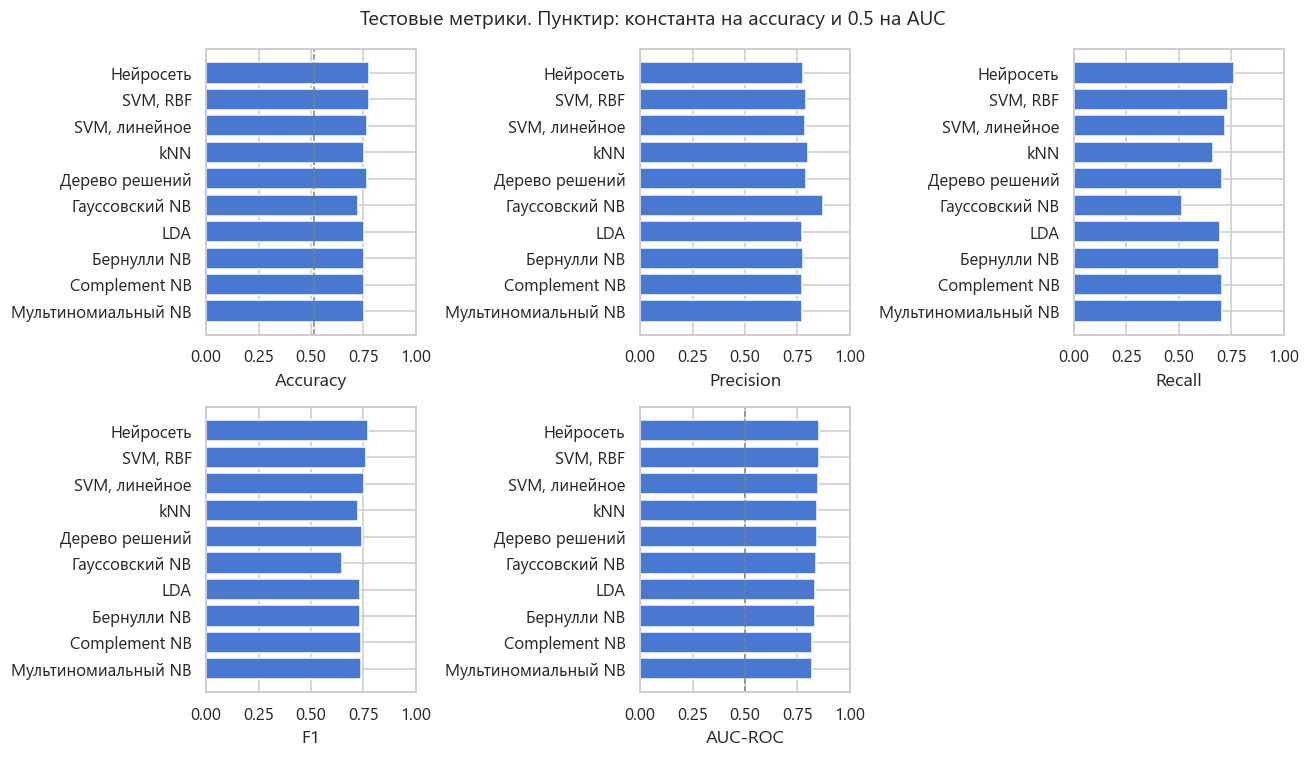

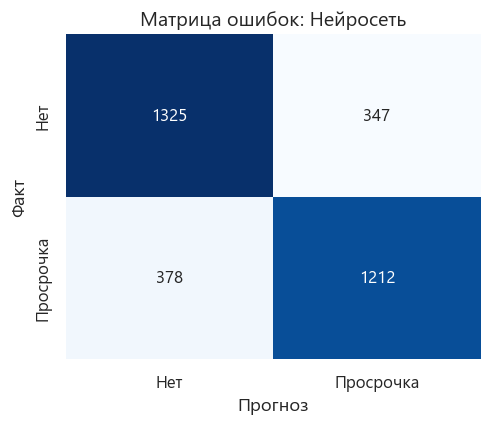

Матрица ошибок, строки — факт, столбцы — прогноз [нет, просрочка]:
                 Прогноз: нет  Прогноз: просрочка
Факт: нет                1325                 347
Факт: просрочка           378                1212
Лучшая тестовая AUC: Нейросеть, 0.8544
Лучший тестовый F1: Нейросеть, 0.7698


In [11]:
def binary_metrics(y_true, y_pred, y_score):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "AUC-ROC": roc_auc_score(y_true, y_score),
    }


rows = []
roc_scores = {}
for name, model in MODELS.items():
    Xte = TEST_X[name]
    pred = model.predict(Xte)
    if SCORE_KIND[name] == "proba":
        score = model.predict_proba(Xte)[:, 1]
    else:
        score = np.asarray(model.decision_function(Xte)).ravel()
    row = binary_metrics(y_test, pred, score)
    row["Модель"] = name
    row["AUC на подборе"] = CV_AUC[name]
    rows.append(row)
    roc_scores[name] = score

row = binary_metrics(y_test, nn_pred, nn_score)
row["Модель"] = "Нейросеть"
row["AUC на подборе"] = CV_AUC["Нейросеть"]
rows.append(row)
roc_scores["Нейросеть"] = nn_score

majority_pred = np.zeros_like(y_test)
majority_acc = accuracy_score(y_test, majority_pred)
base = {
    "Модель": "Константа, класс 0",
    "Accuracy": majority_acc,
    "Precision": 0.0,
    "Recall": 0.0,
    "F1": 0.0,
    "AUC-ROC": 0.5,
    "AUC на подборе": np.nan,
}
rows.append(base)

table = pd.DataFrame(rows).set_index("Модель")
table = table.sort_values("AUC-ROC", ascending=False)
col_order = ["Accuracy", "Precision", "Recall", "F1", "AUC-ROC", "AUC на подборе"]
table = table[col_order]
print("ТЕСТОВЫЕ МЕТРИКИ")
print(table.round(4).to_string())
print("\nВыбранные параметры:")
for name, params in CHOSEN.items():
    print(f"  {name}: {params}, подбор AUC {CV_AUC[name]:.4f}")

ranked = table.drop(index="Константа, класс 0")
fig, ax = plt.subplots(figsize=(7.6, 5.6))
for name in ranked.sort_values("AUC-ROC", ascending=True).index:
    score = roc_scores[name]
    fpr, tpr, _ = roc_curve(y_test, score)
    ax.plot(fpr, tpr, label=f"{name} ({ranked.loc[name, 'AUC-ROC']:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Случайный уровень")
ax.set_xlabel("Доля ложных тревог")
ax.set_ylabel("Recall просрочки")
ax.set_title("ROC на тестовой выборке")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

metric_names = ["Accuracy", "Precision", "Recall", "F1", "AUC-ROC"]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
order = ranked["AUC-ROC"].sort_values(ascending=True).index
for ax, metric in zip(axes.ravel(), metric_names):
    vals = ranked.loc[order, metric]
    ax.barh(order, vals, color="C0")
    ax.set_xlabel(metric)
    ax.set_xlim(0, 1)
    if metric == "Accuracy":
        ax.axvline(majority_acc, color="gray", linestyle="--", linewidth=1)
    if metric == "AUC-ROC":
        ax.axvline(0.5, color="gray", linestyle="--", linewidth=1)
axes.ravel()[-1].axis("off")
fig.suptitle("Тестовые метрики. Пунктир: константа на accuracy и 0.5 на AUC")
fig.tight_layout()
plt.show()

best_name = ranked["AUC-ROC"].idxmax()
if best_name == "Нейросеть":
    best_pred = nn_pred
else:
    model = MODELS[best_name]
    best_pred = model.predict(TEST_X[best_name])
cm = confusion_matrix(y_test, best_pred)
fig, ax = plt.subplots(figsize=(4.6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
    xticklabels=["Нет", "Просрочка"], yticklabels=["Нет", "Просрочка"],
)
ax.set_xlabel("Прогноз")
ax.set_ylabel("Факт")
ax.set_title(f"Матрица ошибок: {best_name}")
fig.tight_layout()
plt.show()
print("Матрица ошибок, строки — факт, столбцы — прогноз [нет, просрочка]:")
print(pd.DataFrame(
    cm,
    index=["Факт: нет", "Факт: просрочка"],
    columns=["Прогноз: нет", "Прогноз: просрочка"],
).to_string())
print(f"Лучшая тестовая AUC: {best_name}, {ranked.loc[best_name, 'AUC-ROC']:.4f}")
print(f"Лучший тестовый F1: {ranked['F1'].idxmax()}, {ranked['F1'].max():.4f}")

### Вывод по сравнению

На тесте модели стоят плотной группой по AUC и заметно расходятся по тому, как порог 0.5 режет precision и recall. Константа «просрочки нет» даёт accuracy **0.513**, recall 0 и AUC 0.5. Все обученные модели уходят от неё далеко: нижняя AUC среди обученных моделей — 0.820.

| Модель | Accuracy | Precision | Recall | F1 | AUC |
|---|---:|---:|---:|---:|---:|
| Нейросеть | 0.778 | 0.777 | 0.762 | **0.770** | **0.854** |
| SVM, RBF | 0.777 | 0.791 | 0.736 | 0.762 | 0.853 |
| SVM, линейное | 0.768 | 0.787 | 0.718 | 0.751 | 0.846 |
| kNN | 0.754 | 0.800 | 0.662 | 0.724 | 0.844 |
| Дерево решений | 0.765 | 0.790 | 0.706 | 0.745 | 0.843 |
| Гауссовский NB | 0.726 | **0.872** | 0.513 | 0.646 | 0.841 |
| LDA | 0.751 | 0.771 | 0.696 | 0.732 | 0.836 |
| Бернулли NB | 0.753 | 0.779 | 0.689 | 0.731 | 0.834 |
| Complement NB | 0.755 | 0.771 | 0.707 | 0.738 | 0.820 |
| Мультиномиальный NB | 0.755 | 0.771 | 0.706 | 0.737 | 0.820 |

**Нейросеть** лучше остальных и по AUC (0.854), и по F1 (0.770). Precision и recall у неё почти равны, 0.777 и 0.762: порог 0.5 не завален в одну сторону. Из 1590 тестовых просрочек сеть находит 1212 и пропускает 378. Ложных тревог 347, верно оставленных благополучных анкет 1325. RBF-SVM отстаёт на 0.001 по AUC и на 0.007 по F1. Для практической отсечки это ближайший сосед, не другой класс методов.

Порядок хорошо стыкуется с тем, что гиперпараметры сказали о форме границы. Узкое ядро RBF запоминает выборку и проигрывает. Широкое ядро (\(\gamma = 0.01\)) лучшее среди SVM. Линейный SVM позади него на 0.005-0.007 AUC. Один скрытый слой сети на валидации не хуже трёх. Граница гладкая, сильная нелинейность этим признакам не нужна, но небольшая нелинейность сети и широкого RBF всё же есть: оба обходят линейный SVM.

Гауссовский NB — отдельная строка, которую нельзя читать по одному AUC. AUC 0.841 стоит рядом с деревом, а F1 падает до **0.646**, потому что при пороге 0.5 recall только **0.513** при precision **0.872**. Ранжирование работает, отсечка 0.5 слишком осторожная: модель редко называет анкету рискованной, зато редко ошибается, когда называет. Для задачи «найти просрочку» такой режим слабый, хотя порядок анкет почти такой же, как у дерева.

kNN при \(k = 61\) по AUC рядом с линейными моделями (0.844), но recall 0.662 — самый низкий среди сильных методов, precision 0.800 — один из самых высоких. Большая окрестность сглаживает границу и тоже сдвигает порог в осторожную сторону.

Мультиномиальный NB и ComplementNB совпали до четвёртого знака AUC (0.820). При равных классах complement нечего исправлять, а псевдосчёты мин-макса грубее стандартизированных признаков гауссовского варианта. Бернулли (0.834) посередине: направление признака сохранено, величина лимита выброшена.

Если скор нужно объяснить без сети, рабочая замена — линейный SVM (AUC 0.846) или LDA (0.836). Оба смотрят на одно и то же: высокий лимит, прошлые просрочки, более молодой возраст, более низкий доход. Плата за читаемые коэффициенты — около 0.01-0.02 AUC против сети.

Для этого датасета предпочтительна нейросеть: она лучшая по AUC и по F1, а recall 0.76 при precision 0.78 — ровный компромисс. Отрыв от RBF-SVM маленький, и оба результата держатся на одной и той же гладкой структуре данных, а не на случайном удачном пороге.

## 8. Заключение

На 16307 анкетах Credit Risk Benchmark Dataset сравнены четыре варианта наивного Байеса, дерево решений, LDA, линейный и RBF SVM, k ближайших соседей и полносвязная сеть TensorFlow. Положительный класс — серьёзная просрочка в ближайшие два года, классы почти равны (48.75% против 51.25%).

1. В файле одна оборванная строка и два точных дубликата. Коды 96 и 98 в счётчиках просрочек — не числа просрочек: таких анкет 84, и у 94% из них цель равна 1. Они заменены пропуском и вынесены во флаг. Лимит ограничен двойкой (сырой максимум 22000, таких строк 59), долговая нагрузка при нулевом доходе (174 строки) заполнена медианой обучающей выборки. После этого корреляция лимита с целью вырастает с −0.006 до **+0.466**, корреляция просрочек 30-59 — с 0.120 до 0.346.
2. Разбиение 80/20 со стратификацией и `random_state=42`: **13045 / 3262**, доля просрочки в обеих частях 48.7%. Медианы, 99-е перцентили и стандартизация считаются только по обучению. Подбор параметров — 5 стратифицированных фолдов по AUC, тест до финальной таблицы не открывается.
3. У гауссовского Байеса `var_smoothing` на сетке не действует (CV AUC 0.844). Бернулли по медиане близок к нему (0.837), мультиномиальный и complement совпадают друг с другом (0.822): классы равны, а псевдосчёты грубее исходных признаков. На тесте у GaussianNB AUC 0.841, но при пороге 0.5 recall только 0.513 и F1 0.646.
4. Дерево без ограничения листа дорастает до глубины 30, AUC на обучении 1.00, на фолде 0.687. Рабочая модель — энтропия, глубина 8, лист из 50 объектов, CV AUC 0.841, тест AUC 0.843. Почти половина важности приходится на использование лимита.
5. LDA слабо чувствует shrinkage: максимум 0.838 при 0.3 против 0.837 при нуле. Полная диагонализация ковариации опускает AUC до 0.831. Коэффициенты совпадают со средними по классам: лимит и прошлые просрочки толкают к классу 1, возраст и доход — от него.
6. Линейный SVM не различает \(C\) от 0.01 до 100 (CV AUC 0.847, тест 0.846). У RBF решает \(\gamma\): 0.01 даёт CV AUC 0.852 и тест 0.853, а \(\gamma = 1\) запоминает обучение (AUC 0.939 против 0.812 на фолде). Опорных векторов больше половины выборки, классы перекрываются.
7. kNN требует большую окрестность. Лучшее — \(k = 61\), метрика и схема весов почти ничего не меняют, CV и тест AUC 0.844. AUC на обучении равна 1 из-за нулевого расстояния до самой точки при весах `distance`, к качеству это числа отношения не имеет. Recall на тесте 0.662.
8. Сеть: один выход с сигмоидой, потеря — бинарная кросс-энтропия, оптимизатор Adam. Десять опытов по эпохам, батчу, глубине, ширине, активации и dropout укладываются в валидационную AUC **0.858-0.860**. Глубже одного слоя идти незачем, dropout и размер батча качество не двигают, sigmoid за 30 эпох чуть медленнее ReLU. Финальная модель — 32 нейрона, ReLU, dropout 0.2, батч 64, 14 эпох. Кривые лежат в ноутбуке и в TensorBoard (`tensorboard --logdir logs`).
9. На тесте лучшая модель — **нейросеть: accuracy 0.778, precision 0.777, recall 0.762, F1 0.770, AUC 0.854**. Следом RBF-SVM (AUC 0.853, F1 0.762). Отрыв маленький, потому что граница гладкая. Для этого датасета сеть предпочтительна как лучший компромисс precision и recall. Если нужен читаемый скор без Keras, его заменяет линейный SVM (AUC 0.846) с теми же четырьмя сигналами: лимит, прошлые просрочки, возраст, доход.

## 9. Список источников

1. Credit Risk Benchmark Dataset. Kaggle: https://www.kaggle.com/datasets/adilshamim8/credit-risk-benchmark-dataset
2. Give Me Some Credit. Соревнование Kaggle, 2011: https://www.kaggle.com/c/GiveMeSomeCredit
3. Hastie T., Tibshirani R., Friedman J. The Elements of Statistical Learning. - 2nd ed. - Springer, 2009.
4. Bishop C. M. Pattern Recognition and Machine Learning. - Springer, 2006.
5. Джеймс Г., Уиттен Д., Хасти Т., Тибширани Р. Введение в статистическое обучение. - М.: ДМК Пресс, 2016.
6. Rennie J. D. M., Shih L., Teevan J., Karger D. R. Tackling the Poor Assumptions of Naive Bayes Text Classifiers // ICML. - 2003. - Описание complement naive Bayes.
7. Cortes C., Vapnik V. Support-vector networks // Machine Learning. - 1995. - Vol. 20. - P. 273-297.
8. Fawcett T. An introduction to ROC analysis // Pattern Recognition Letters. - 2006. - Vol. 27. - P. 861-874.
9. Goodfellow I., Bengio Y., Courville A. Deep Learning. - MIT Press, 2016.
10. Документация scikit-learn, методы классификации: https://scikit-learn.org/stable/supervised_learning.html
11. Документация TensorFlow, Keras и TensorBoard: https://www.tensorflow.org/tensorboard/get_started

## 10. Приложение

Полный листинг - кодовые ячейки этого ноутбука в порядке выполнения: загрузка, очистка, разбиение и три представления признаков, сетки наивного Байеса, дерева, LDA, SVM и kNN, опыты нейронной сети, общая таблица метрик, ROC и столбчатые диаграммы. Отдельный дублирующий файл с тем же кодом не прикладывается.

Журналы TensorBoard лежат в каталоге `logs/nn/`. Из папки работы они открываются командой `tensorboard --logdir logs`.